# Phân loại trái cây dựa trên hình ảnh

In [1]:
import os
import shutil
import gc                    
from tqdm import tqdm         

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.svm import SVC
from sklearn.decomposition import PCA

import tensorflow as tf
from keras.models import Sequential, Model
from keras.layers import Lambda
from keras.layers import (Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization, Rescaling, GlobalAveragePooling2D, RandomFlip, RandomRotation, RandomZoom, RandomTranslation, RandomContrast, RandomBrightness)
from keras.optimizers import Adam
from keras.callbacks import (EarlyStopping, ModelCheckpoint, BackupAndRestore, CSVLogger)
from keras.utils import to_categorical

from keras.applications import MobileNetV2, EfficientNetB0
from keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess_input
from keras.applications.efficientnet import preprocess_input as efficientnet_preprocess_input

PROJECT_ROOT = os.getcwd()
NPY_FILES = {
    'X_train': os.path.join(PROJECT_ROOT, 'X_train.npy'),
    'y_train': os.path.join(PROJECT_ROOT, 'y_train.npy'),
    'X_test': os.path.join(PROJECT_ROOT, 'X_test.npy'),
    'y_test': os.path.join(PROJECT_ROOT, 'y_test.npy'),
    'class_names': os.path.join(PROJECT_ROOT, 'class_names.npy'),
}

# Runtime tuning: use the GPU when TensorFlow can see it, otherwise keep a safe CPU fallback.
GPUS = tf.config.list_physical_devices('GPU')
USE_GPU = len(GPUS) > 0
for gpu in GPUS:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass

if USE_GPU:
    tf.config.optimizer.set_jit('autoclustering')
    tf.keras.mixed_precision.set_global_policy('mixed_float16')

TRAIN_IMG_SIZE = 160
TRAIN_BATCH_SIZE = 256 if USE_GPU else 64
STEPS_PER_EXECUTION = 32 if USE_GPU else 1
print(f'TensorFlow {tf.__version__} | GPU: {USE_GPU} | devices: {GPUS}')
if not USE_GPU:
    print('TensorFlow/Keras không thấy GPU trên Windows native. Không sao: notebook này sẽ train bằng PyTorch CUDA ở phần Fast GPU CNN.')

# Run-all defaults: train the fast 160x160 PyTorch CUDA model and skip slow Keras transfer-learning cells.
RUN_FAST_GPU_TORCH = True
RUN_SLOW_KERAS_MODELS = False
RUN_DATA_PREP = False  # True để tải/lọc/đóng gói lại dữ liệu từ đầu (cần Internet, Kaggle token, mất ~1 giờ)
TORCH_EPOCHS = 25
TORCH_BATCH_SIZE = 128
TORCH_WORKERS = 0

RUN_KERAS_CPU_CUSTOM_CNN = False


try:
    import torch
    TORCH_CUDA_AVAILABLE = torch.cuda.is_available()
    TORCH_DEVICE_NAME = torch.cuda.get_device_name(0) if TORCH_CUDA_AVAILABLE else 'None'
    print(f'PyTorch CUDA: {TORCH_CUDA_AVAILABLE} | device: {TORCH_DEVICE_NAME}')
except ModuleNotFoundError:
    TORCH_CUDA_AVAILABLE = False
    TORCH_DEVICE_NAME = 'PyTorch chưa được cài'
    print('PyTorch CUDA: False | PyTorch chưa được cài')

RUN_TORCH_TRANSFER_MODELS = True
TORCH_TRANSFER_EPOCHS = 15
TORCH_TRANSFER_BATCH_SIZE = 64
TORCH_USE_PRETRAINED = True
TORCH_FREEZE_BACKBONE = False  # fine-tune toàn bộ backbone

RUN_TORCH_RESNET50 = True
TORCH_RESNET_WARMUP_EPOCHS = 3
TORCH_RESNET_FINETUNE_EPOCHS = 15
TORCH_RESNET_BATCH_SIZE = 64
TORCH_RESNET_FINETUNE_BLOCKS = 3


TensorFlow 2.20.0 | GPU: False | devices: []
TensorFlow/Keras không thấy GPU trên Windows native. Không sao: notebook này sẽ train bằng PyTorch CUDA ở phần Fast GPU CNN.
PyTorch CUDA: True | device: NVIDIA GeForce RTX 4060 Laptop GPU


In [2]:
# Du lieu da duoc dong goi san trong cac file NPY.
# Notebook khong con phu thuoc vao thu muc data/ hoac CSV anh goc.
variety_df = None
IMG_SIZE = 160
SVM_IMG_SIZE = 64  # SVM+PCA dùng ảnh thu nhỏ 64x64 để tiết kiệm RAM
print('Pipeline du lieu: X_train.npy, X_test.npy, y_train.npy, y_test.npy, class_names.npy')


Pipeline du lieu: X_train.npy, X_test.npy, y_train.npy, y_test.npy, class_names.npy


## 0. Nguồn dữ liệu và cách chuẩn bị

Dữ liệu được lấy từ bộ dữ liệu Kaggle, crawl thêm ảnh từ Wikimedia Commons, rồi xử lý theo các bước sau:

| Bước | Nội dung |
|---|---|
| 1 | Tải ảnh từ Wikimedia Commons cho từng nhóm trong `fruit_groups.py` |
| 2 | Nhập ảnh Kaggle `kritikseth/fruit-and-vegetable-image-recognition`  |
| 3 | CLIP kiểm tra, chỉ giữ ảnh đúng nhóm (loại tranh, cây, ảnh lạc đề) |
| 4 | Khử ảnh trùng, chia train/test phân tầng, đóng gói `X_train.npy`... 160x160 |


In [3]:
# Chỉ chạy khi cần tái tạo dữ liệu từ đầu (mặc định đã có sẵn các file NPY).
import subprocess, sys
if RUN_DATA_PREP:
    for script in ['download_web_images.py', 'import_kaggle_images.py', 'filter_web_images.py', 'prepare_dataset.py']:
        print('Chạy', script, flush=True)
        subprocess.run([sys.executable, script], check=True)
else:
    print('RUN_DATA_PREP=False: dùng các file NPY đã đóng gói sẵn.')


RUN_DATA_PREP=False: dùng các file NPY đã đóng gói sẵn.


## 1. Thiết kế thí nghiệm

| Nhóm | Nội dung |
|---|---|
| Dữ liệu | ~45 nhóm trái cây/rau củ, ảnh thật từ web (Wikimedia Commons + Kaggle), CLIP lọc nhãn sai, khử trùng lặp |
| Baseline truyền thống | SVM + PCA trên ảnh thu nhỏ 64x64 để giảm chi phí bộ nhớ |
| Deep learning tự xây dựng | Custom CNN dùng cùng pipeline `tf.data` |
| Transfer learning | MobileNetV2, EfficientNetB0, ResNet50 với ảnh 160x160, fine-tune toàn bộ |
| Đánh giá | Accuracy, macro F1, confusion matrix, ROC/AUC, top-k accuracy, phân tích lớp khó |
| Demo | Dự đoán ảnh thật và giao diện Gradio upload ảnh |

Cách trình bày này giúp tách rõ baseline, mô hình tự xây dựng và hai mô hình pre-trained để khi bảo vệ có thể giải thích từng bước.

## 2. Nạp dữ liệu và tiền xử lý cho baseline SVM

In [4]:
def load_data_from_npy(project_root=PROJECT_ROOT):
    required = ['X_train', 'y_train', 'X_test', 'y_test', 'class_names']
    missing = [name for name in required if not os.path.exists(NPY_FILES[name])]
    if missing:
        raise FileNotFoundError(
            'Thieu file NPY: ' + ', '.join(missing) +
            '. Hay dat cac file NPY cung thu muc voi notebook.'
        )

    x_train = np.load(NPY_FILES['X_train'], mmap_mode='r')
    y_train = np.load(NPY_FILES['y_train'], mmap_mode='r')
    x_test = np.load(NPY_FILES['X_test'], mmap_mode='r')
    y_test = np.load(NPY_FILES['y_test'], mmap_mode='r')
    class_names = np.load(NPY_FILES['class_names'], allow_pickle=True).astype(str)
    return x_train, y_train, x_test, y_test, class_names


In [5]:
# Kiem tra bo NPY truoc khi chay cac cell phia sau.
X_train, y_train, X_test, y_test, class_names = load_data_from_npy()
print(
    f'Da san sang bo NPY: train={len(X_train)} anh, '
    f'test={len(X_test)} anh, kich thuoc={X_train.shape[1:]}'
)


Da san sang bo NPY: train=4106 anh, test=725 anh, kich thuoc=(160, 160, 3)


In [6]:
# Nap NPY dang memory-map de tiet kiem RAM.
X_train, y_train, X_test, y_test, class_names = load_data_from_npy()
print(f'Nap NPY thanh cong! Train: {X_train.shape[0]} anh, Test: {X_test.shape[0]} anh.')
print(f'Kich thuoc anh cache: {X_train.shape[1]}x{X_train.shape[2]}')


Nap NPY thanh cong! Train: 4106 anh, Test: 725 anh.
Kich thuoc anh cache: 160x160


## 3. Khám phá dữ liệu ban đầu

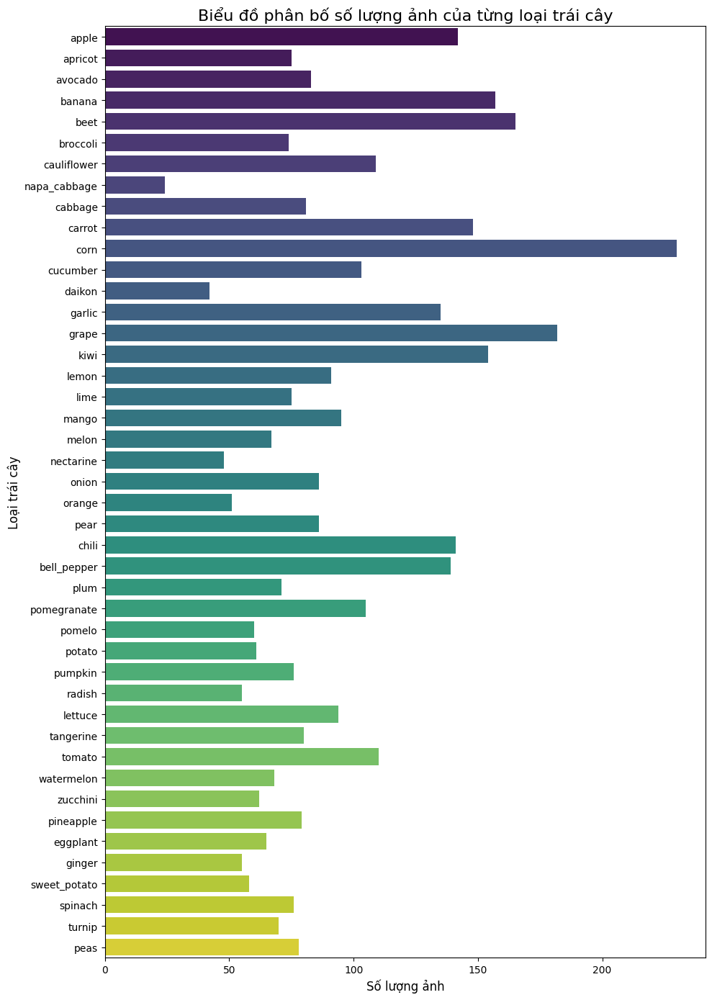

In [7]:
# Đếm số lượng ảnh của từng loại trong tập Train
unique_classes, counts = np.unique(y_train, return_counts=True)
class_labels = [class_names[i] for i in unique_classes]

plt.figure(figsize=(10, 14))

sns.barplot(x=counts, y=class_labels, hue=class_labels, palette='viridis', legend=False)

plt.title('Biểu đồ phân bố số lượng ảnh của từng loại trái cây', fontsize=16)
plt.xlabel('Số lượng ảnh', fontsize=12)
plt.ylabel('Loại trái cây', fontsize=12)

plt.tight_layout()
plt.show()

## 4. Trực quan hóa dữ liệu nâng cao

Các biểu đồ dưới đây giúp nhìn dữ liệu ở nhiều góc hơn: độ cân bằng giữa các lớp, mẫu ảnh thực tế, phân bố màu RGB và ảnh trung bình đại diện cho một số lớp.

Thống kê nhanh về số lượng ảnh mỗi lớp:
Train: min=24, max=230, mean=93.3
Test : min=5, max=40, mean=16.5


,class_name,train_count,test_count,total_count,test/train_ratio
10,corn,230,40,270,0.173913
14,grape,182,32,214,0.175824
4,beet,165,29,194,0.175758
3,banana,157,28,185,0.178344
15,kiwi,154,27,181,0.175325
9,carrot,148,26,174,0.175676
0,apple,142,25,167,0.176056
24,chili,141,25,166,0.177305
25,bell_pepper,139,25,164,0.179856
13,garlic,135,24,159,0.177778


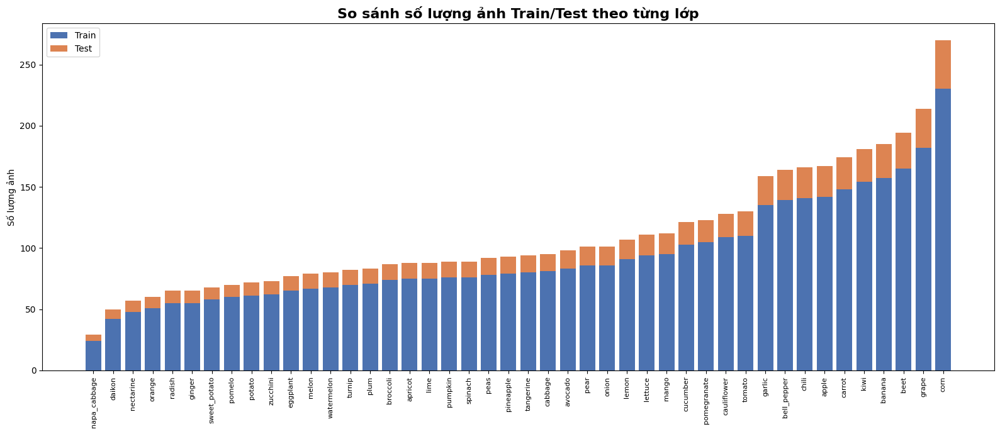

In [8]:
# So sánh số lượng ảnh Train/Test theo từng lớp
from IPython.display import display

train_counts = np.bincount(y_train.astype(int), minlength=len(class_names))
test_counts = np.bincount(y_test.astype(int), minlength=len(class_names))

df_distribution = pd.DataFrame({
    'class_name': class_names,
    'train_count': train_counts,
    'test_count': test_counts,
    'total_count': train_counts + test_counts
})
df_distribution['test/train_ratio'] = df_distribution['test_count'] / df_distribution['train_count'].replace(0, np.nan)
df_distribution = df_distribution.sort_values('total_count', ascending=False)

print('Thống kê nhanh về số lượng ảnh mỗi lớp:')
print(f"Train: min={train_counts.min()}, max={train_counts.max()}, mean={train_counts.mean():.1f}")
print(f"Test : min={test_counts.min()}, max={test_counts.max()}, mean={test_counts.mean():.1f}")
display(df_distribution.head(10))

plot_df = df_distribution.sort_values('train_count', ascending=True)
x = np.arange(len(plot_df))

plt.figure(figsize=(16, 7))
plt.bar(x, plot_df['train_count'], label='Train', color='#4C72B0')
plt.bar(x, plot_df['test_count'], bottom=plot_df['train_count'], label='Test', color='#DD8452')
plt.xticks(x, plot_df['class_name'], rotation=90, fontsize=8)
plt.ylabel('Số lượng ảnh')
plt.title('So sánh số lượng ảnh Train/Test theo từng lớp', fontsize=16, fontweight='bold')
plt.legend()
plt.tight_layout()
plt.show()


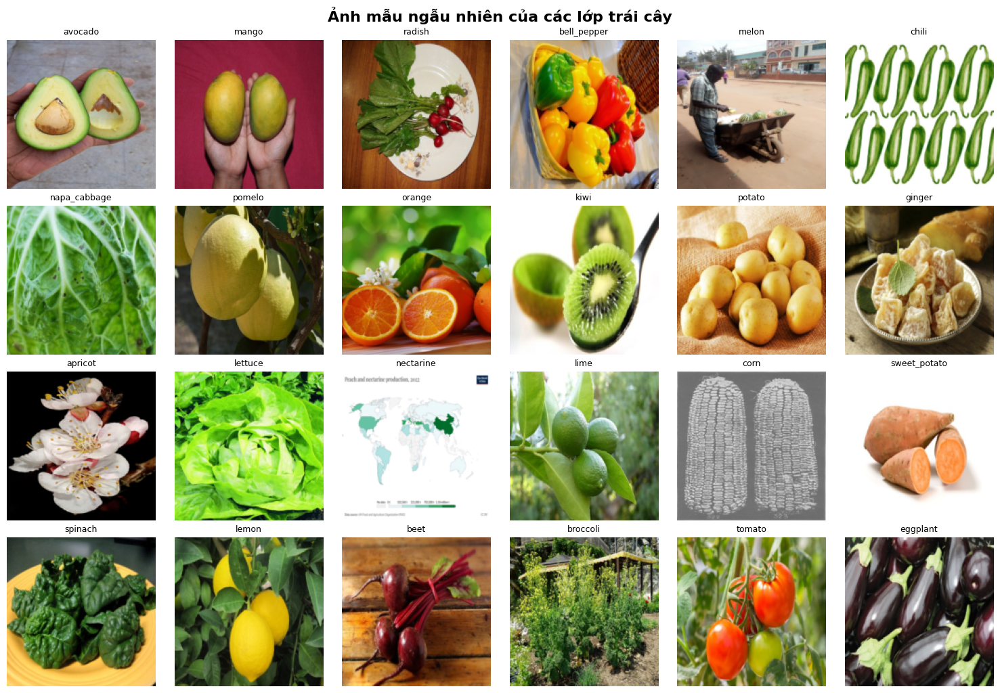

In [9]:
# Hiển thị ảnh mẫu ngẫu nhiên từ nhiều lớp
rng = np.random.default_rng(42)
classes_to_show = rng.choice(np.arange(len(class_names)), size=min(24, len(class_names)), replace=False)

cols = 6
rows = int(np.ceil(len(classes_to_show) / cols))
plt.figure(figsize=(15, rows * 2.6))

for plot_idx, class_idx in enumerate(classes_to_show, start=1):
    image_indices = np.where(y_train == class_idx)[0]
    if len(image_indices) == 0:
        continue

    selected_idx = rng.choice(image_indices)
    image = np.clip(X_train[selected_idx], 0, 255).astype(np.uint8)

    plt.subplot(rows, cols, plot_idx)
    plt.imshow(image)
    plt.axis('off')
    plt.title(class_names[class_idx], fontsize=9)

plt.suptitle('Ảnh mẫu ngẫu nhiên của các lớp trái cây', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()


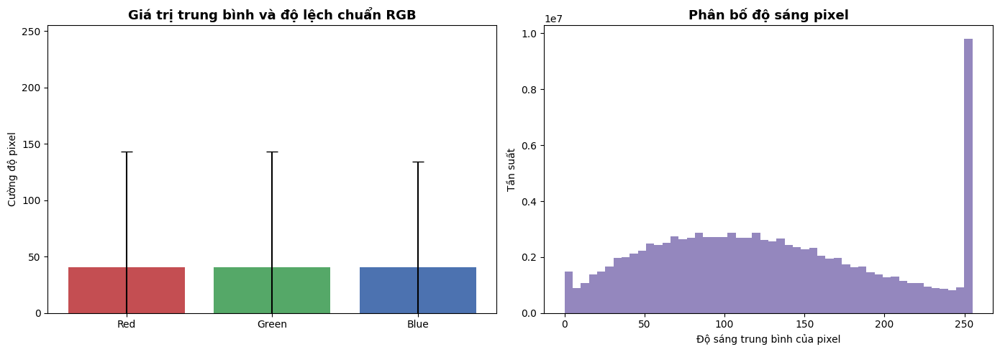

RGB mean: [40.86 40.86 40.86]
RGB std : [102.28 102.28  93.36]


In [10]:
# Phân tích phân bố độ sáng và màu RGB trên một mẫu dữ liệu
sample_size = min(5000, len(X_train))
sample_indices = np.random.default_rng(42).choice(len(X_train), size=sample_size, replace=False)
X_sample = X_train[sample_indices].astype(np.float32)

channel_means = X_sample.mean(axis=(0, 1, 2))
channel_stds = X_sample.std(axis=(0, 1, 2))
brightness = X_sample.mean(axis=3).ravel()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(['Red', 'Green', 'Blue'], channel_means, yerr=channel_stds, color=['#C44E52', '#55A868', '#4C72B0'], capsize=6)
axes[0].set_title('Giá trị trung bình và độ lệch chuẩn RGB', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Cường độ pixel')
axes[0].set_ylim(0, 255)

axes[1].hist(brightness, bins=50, color='#8172B3', alpha=0.85)
axes[1].set_title('Phân bố độ sáng pixel', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Độ sáng trung bình của pixel')
axes[1].set_ylabel('Tần suất')

plt.tight_layout()
plt.show()

print('RGB mean:', np.round(channel_means, 2))
print('RGB std :', np.round(channel_stds, 2))


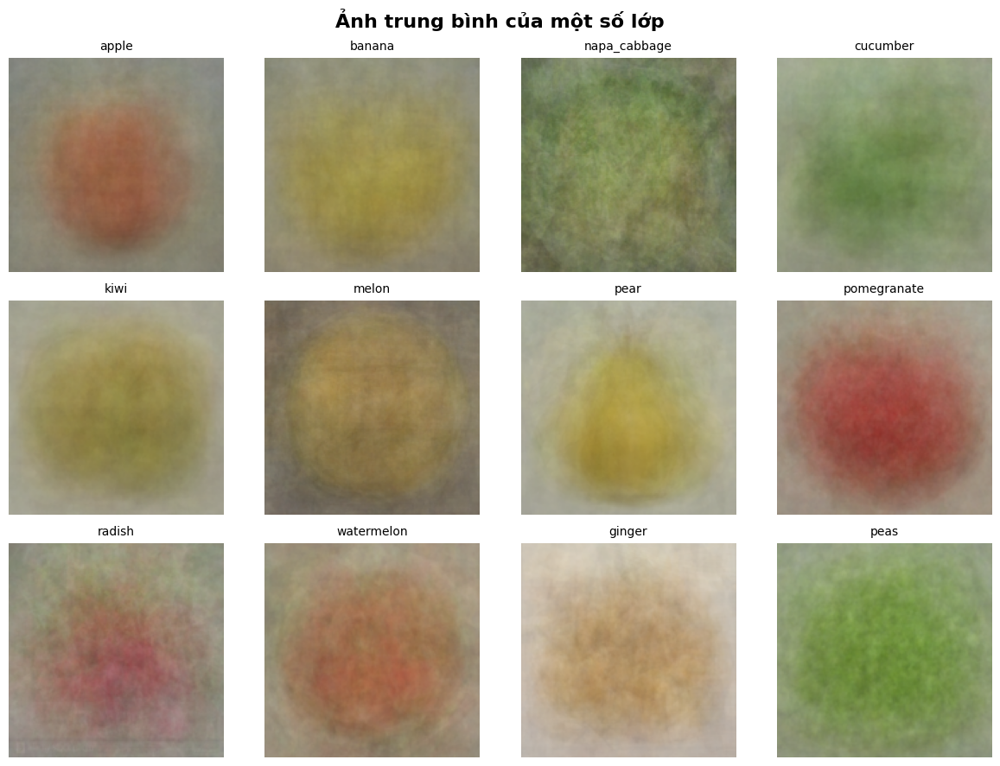

In [11]:
# Ảnh trung bình đại diện cho một số lớp
# Ảnh trung bình giúp thấy màu sắc/hình dạng đặc trưng chung của từng loại trái cây.
classes_for_mean = np.linspace(0, len(class_names) - 1, num=min(12, len(class_names)), dtype=int)

cols = 4
rows = int(np.ceil(len(classes_for_mean) / cols))
plt.figure(figsize=(12, rows * 3))

for plot_idx, class_idx in enumerate(classes_for_mean, start=1):
    class_images = X_train[y_train == class_idx]
    if len(class_images) == 0:
        continue

    mean_image = np.clip(class_images.mean(axis=0), 0, 255).astype(np.uint8)
    plt.subplot(rows, cols, plot_idx)
    plt.imshow(mean_image)
    plt.axis('off')
    plt.title(class_names[class_idx], fontsize=10)

plt.suptitle('Ảnh trung bình của một số lớp', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()


### Dashboard cân bằng dữ liệu

Biểu đồ này giúp giải thích lớp nào có nhiều/ít ảnh, từ đó liên hệ đến lỗi sai và macro F1.

Tổng số lớp: 44
Tổng ảnh train: 4106
Tổng ảnh test: 725
Mức mất cân bằng train: lớp nhiều nhất / ít nhất = 9.58 lần


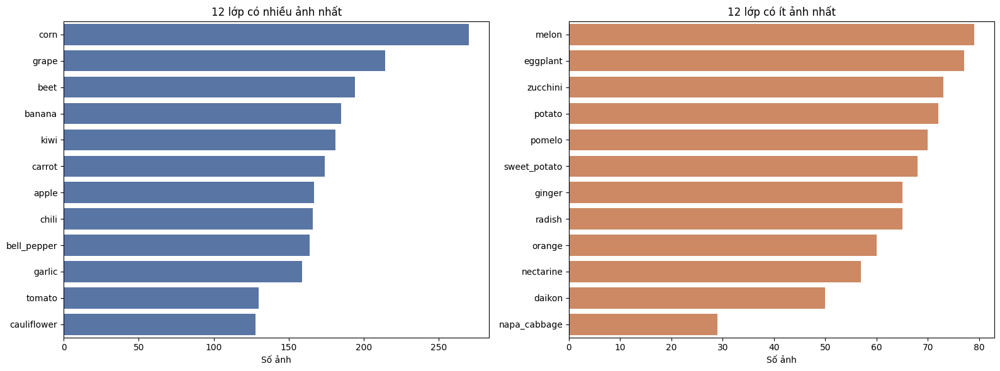

,class_name,train_count,test_count,total_count
10,corn,230,40,270
14,grape,182,32,214
4,beet,165,29,194
3,banana,157,28,185
15,kiwi,154,27,181
9,carrot,148,26,174
0,apple,142,25,167
24,chili,141,25,166
25,bell_pepper,139,25,164
13,garlic,135,24,159


In [12]:
# Dashboard nhanh về độ cân bằng dữ liệu
train_counts = np.bincount(y_train.astype(int), minlength=len(class_names))
test_counts = np.bincount(y_test.astype(int), minlength=len(class_names))

eda_df = pd.DataFrame({
    'class_name': class_names,
    'train_count': train_counts,
    'test_count': test_counts,
    'total_count': train_counts + test_counts
}).sort_values('total_count', ascending=False)

print('Tổng số lớp:', len(class_names))
print('Tổng ảnh train:', int(train_counts.sum()))
print('Tổng ảnh test:', int(test_counts.sum()))
print(f"Mức mất cân bằng train: lớp nhiều nhất / ít nhất = {train_counts.max() / max(train_counts.min(), 1):.2f} lần")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(data=eda_df.head(12), x='total_count', y='class_name', ax=axes[0], color='#4C72B0')
axes[0].set_title('12 lớp có nhiều ảnh nhất')
axes[0].set_xlabel('Số ảnh')
axes[0].set_ylabel('')

sns.barplot(data=eda_df.tail(12), x='total_count', y='class_name', ax=axes[1], color='#DD8452')
axes[1].set_title('12 lớp có ít ảnh nhất')
axes[1].set_xlabel('Số ảnh')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

display(eda_df.head(10))


## 5. Thuật toán 1: SVM + PCA

SVM đóng vai trò baseline truyền thống. Ảnh được giảm chiều bằng PCA trước khi phân loại để so sánh với các mô hình deep learning.

In [13]:
max_train_samples = 12000
if len(X_train) > max_train_samples:

    X_train_sub, _, y_train_sub, _ = train_test_split(
        X_train, y_train, train_size=max_train_samples, stratify=y_train, random_state=42
    )
else:
    X_train_sub, y_train_sub = X_train, y_train

max_test_samples = 3000
if len(X_test) > max_test_samples:
    X_test_sub, _, y_test_sub, _ = train_test_split(
        X_test, y_test, train_size=max_test_samples, stratify=y_test, random_state=42
    )
else:
    X_test_sub, y_test_sub = X_test, y_test

print(f"Số lượng ảnh đưa vào SVM: Train = {len(X_train_sub)}, Test = {len(X_test_sub)}")

# Thu nhỏ về SVM_IMG_SIZE để PCA/SVM không tốn RAM với ảnh 160x160
def shrink(images):
    return np.stack([cv2.resize(np.asarray(im, dtype=np.uint8), (SVM_IMG_SIZE, SVM_IMG_SIZE), interpolation=cv2.INTER_AREA) for im in images])

X_train_sub = shrink(X_train_sub)
X_test_sub = shrink(X_test_sub)

# 2. CHIA 255 CHO TẬP DỮ LIỆU NHỎ (Tiết kiệm tối đa RAM)
print("Đang chuẩn hóa (Normalize)")
X_train_sub = X_train_sub.astype(np.float32) / 255.0
X_test_sub = X_test_sub.astype(np.float32) / 255.0

del X_train, X_test 
gc.collect() 

# 3. CHẠY PCA 
print("Đang áp dụng PCA ")
X_train_sub_flat = X_train_sub.reshape(X_train_sub.shape[0], -1)
X_test_sub_flat = X_test_sub.reshape(X_test_sub.shape[0], -1)

# Chạy PCA trên dữ liệu đã băm phẳng
pca = PCA(n_components=0.95)
X_train_pca = pca.fit_transform(X_train_sub_flat)
X_test_pca = pca.transform(X_test_sub_flat)

print(f"Số lượng chiều dữ liệu sau PCA: {X_train_pca.shape[1]}")
print("Đang huấn luyện mô hình SVM.")

svm_model = SVC(kernel='rbf', C=1.0, probability=True) # 
svm_model.fit(X_train_pca, y_train_sub)

# đánh giá
y_pred_svm = svm_model.predict(X_test_pca)
acc_svm = accuracy_score(y_test_sub, y_pred_svm)
print(f"\n Độ chính xác: {acc_svm * 100:.2f}%")

Số lượng ảnh đưa vào SVM: Train = 4106, Test = 725
Đang chuẩn hóa (Normalize)
Đang áp dụng PCA 
Số lượng chiều dữ liệu sau PCA: 563
Đang huấn luyện mô hình SVM.

 Độ chính xác: 19.86%


## 6. Pipeline dữ liệu cho Deep Learning

Phần này tạo `tf.data` pipeline ở kích thước `160x160`, kèm augmentation để mô hình học tốt hơn với thay đổi góc chụp, vị trí và ánh sáng.

In [14]:
# Tao tf.data truc tiep tu NPY, khong doc lai thu muc anh goc.
# Cell nay nap lai memory-map vi cell SVM phia tren co the da xoa X_train/X_test.
X_train, y_train, X_test, y_test, class_names = load_data_from_npy()
valid_classes = np.asarray(class_names).astype(str).tolist()
all_classes = list(valid_classes)
NUM_CLASSES = len(valid_classes)
BATCH_SIZE = TRAIN_BATCH_SIZE

train_indices, val_indices = train_test_split(
    np.arange(len(y_train)),
    test_size=0.2,
    stratify=np.asarray(y_train),
    random_state=123,
)

AUTOTUNE = tf.data.AUTOTUNE


def make_npy_tf_dataset(images, labels, indices, batch_size, shuffle=False):
    indices = np.asarray(indices, dtype=np.int64)

    def generator():
        order = indices.copy()
        if shuffle:
            np.random.default_rng().shuffle(order)
        for index in order:
            image = np.asarray(images[int(index)], dtype=np.float32)
            one_hot = np.zeros(NUM_CLASSES, dtype=np.float32)
            one_hot[int(labels[int(index)])] = 1.0
            yield image, one_hot

    dataset = tf.data.Dataset.from_generator(
        generator,
        output_signature=(
            tf.TensorSpec(shape=(TRAIN_IMG_SIZE, TRAIN_IMG_SIZE, 3), dtype=tf.float32),
            tf.TensorSpec(shape=(NUM_CLASSES,), dtype=tf.float32),
        ),
    )
    return dataset.batch(batch_size, drop_remainder=False)


train_ds = make_npy_tf_dataset(
    X_train, y_train, train_indices, BATCH_SIZE, shuffle=True
)
val_ds = make_npy_tf_dataset(
    X_train, y_train, val_indices, BATCH_SIZE, shuffle=False
)
test_ds = make_npy_tf_dataset(
    X_test, y_test, np.arange(len(y_test)), BATCH_SIZE, shuffle=False
)

# Augmentation chi ap dung cho tap train.
data_augmentation = Sequential([
    RandomFlip('horizontal'),
    RandomRotation(0.03),
    RandomZoom(0.08),
])


def prepare_train(image, label):
    return data_augmentation(image, training=True), label


def prepare_test(image, label):
    return image, label


train_ds = train_ds.map(prepare_train, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
val_ds = val_ds.map(prepare_test, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
test_ds = test_ds.map(prepare_test, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

print(f'Tao tf.data tu NPY xong: train={len(train_indices)}, val={len(val_indices)}, test={len(y_test)}')


Tao tf.data tu NPY xong: train=3284, val=822, test=725


### Kiểm tra trực quan augmentation

Cell này cho thấy augmentation không chỉ là tham số trong code mà thật sự tạo ra biến thể ảnh dùng khi huấn luyện.

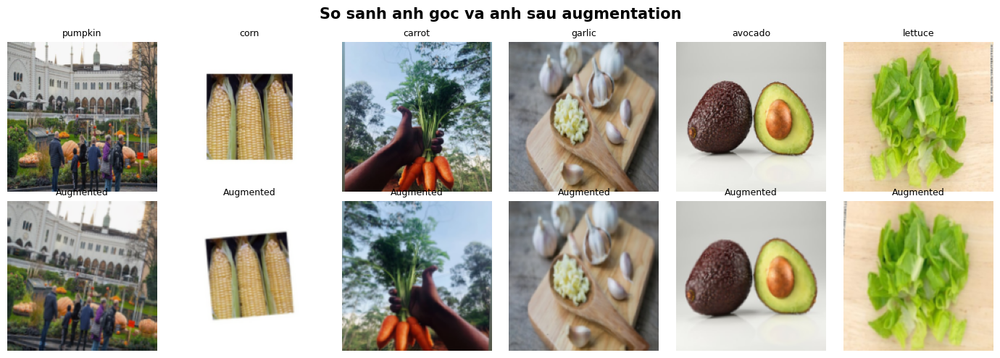

In [15]:
# Minh hoa augmentation tu du lieu NPY.
preview_ds = make_npy_tf_dataset(
    X_train, y_train, train_indices, batch_size=6, shuffle=True
)
preview_images, preview_labels = next(iter(preview_ds))
augmented_images = data_augmentation(preview_images, training=True)

plt.figure(figsize=(14, 5))
for i in range(min(6, preview_images.shape[0])):
    label_idx = int(np.argmax(preview_labels[i].numpy()))

    plt.subplot(2, 6, i + 1)
    plt.imshow(preview_images[i].numpy().astype('uint8'))
    plt.title(class_names[label_idx], fontsize=9)
    plt.axis('off')

    plt.subplot(2, 6, i + 7)
    plt.imshow(np.clip(augmented_images[i].numpy(), 0, 255).astype('uint8'))
    plt.title('Augmented', fontsize=9)
    plt.axis('off')

plt.suptitle('So sanh anh goc va anh sau augmentation', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()


In [16]:
# GPU training utilities 
import json
import math
import time
from pathlib import Path

try:
    import torch
    import torch.nn.functional as F
    from torch import nn
    from torch.utils.data import DataLoader, Dataset
    from torchvision.models import (
        EfficientNet_B0_Weights,
        MobileNet_V2_Weights,
        ResNet50_Weights,
        efficientnet_b0,
        mobilenet_v2,
        resnet50,
    )
except ModuleNotFoundError as exc:
    raise ModuleNotFoundError(
        'Thiếu PyTorch/torchvision CUDA. Cài bằng pip CUDA wheel trước khi train GPU.'
    ) from exc


MODEL_CONFIG = {
    'fast_cnn': {
        'display_name': 'Fast GPU CNN',
        'checkpoint': 'fast_cnn_web.pt',
        'metadata': 'fast_cnn_web_metadata.json',
    },
    'mobilenetv2': {
        'display_name': 'MobileNetV2',
        'checkpoint': 'mobilenetv2_web.pt',
        'metadata': 'mobilenetv2_web_metadata.json',
    },
    'efficientnetb0': {
        'display_name': 'EfficientNetB0',
        'checkpoint': 'efficientnetb0_web.pt',
        'metadata': 'efficientnetb0_web_metadata.json',
    },
    'resnet50': {
        'display_name': 'ResNet50',
        'checkpoint': 'resnet50_web.pt',
        'metadata': 'resnet50_web_metadata.json',
    },
}


class NpyImageDataset(Dataset):
    def __init__(self, x_path, y_path, indices=None):
        self.x_path = x_path
        self.y_path = y_path
        self.images = np.load(self.x_path, mmap_mode='r')
        self.labels = np.load(self.y_path, mmap_mode='r')
        self.indices = np.asarray(indices) if indices is not None else np.arange(len(self.labels))

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, item):
        idx = int(self.indices[item])
        image = torch.from_numpy(np.array(self.images[idx], dtype=np.float32, copy=True))
        image = image.permute(2, 0, 1).div_(255.0)
        label = torch.tensor(int(self.labels[idx]), dtype=torch.long)
        return image, label


class FastFruitCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.features = nn.Sequential(
            self._block(3, 32),
            self._block(32, 64),
            self._block(64, 128),
            self._block(128, 192),
            nn.AdaptiveAvgPool2d(1),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.25),
            nn.Linear(192, num_classes),
        )

    @staticmethod
    def _block(in_channels, out_channels):
        return nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.SiLU(inplace=True),
            nn.MaxPool2d(2),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


class ImageNetNormalize(nn.Module):
    def __init__(self):
        super().__init__()
        self.register_buffer('mean', torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer('std', torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def forward(self, images):
        return (images - self.mean) / self.std


class TorchHistory:
    def __init__(self, rows):
        self.history = {
            'loss': [row['train_loss'] for row in rows],
            'accuracy': [row['train_accuracy'] for row in rows],
            'val_loss': [row['val_loss'] for row in rows],
            'val_accuracy': [row['val_accuracy'] for row in rows],
        }


class TorchPredictWrapper:
    def __init__(self, model, class_names, device=None, image_size=64):
        self.model = model
        self.class_names = np.asarray(class_names).astype(str)
        self.device = device or torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        self.input_shape = (None, image_size, image_size, 3)
        self.trainable_weights = list(model.parameters())
        self.non_trainable_weights = []
        self.model.to(self.device)
        self.model.eval()

    def _predict_array(self, images, batch_size=1024):
        arr = np.asarray(images, dtype=np.float32)
        if arr.ndim == 3:
            arr = arr[None, ...]
        outputs = []
        with torch.inference_mode():
            for start in range(0, len(arr), batch_size):
                batch = torch.from_numpy(arr[start:start + batch_size]).permute(0, 3, 1, 2).div(255.0)
                batch = batch.to(self.device, memory_format=torch.channels_last)
                logits = self.model(batch)
                outputs.append(torch.softmax(logits, dim=1).detach().cpu().numpy())
        return np.concatenate(outputs, axis=0)

    def predict(self, data, verbose=0, batch_size=1024):
        if hasattr(data, 'numpy'):
            data = data.numpy()
        if isinstance(data, np.ndarray):
            return self._predict_array(data, batch_size=batch_size)
        outputs = []
        for images, _ in data:
            if hasattr(images, 'numpy'):
                images = images.numpy()
            outputs.append(self._predict_array(images, batch_size=batch_size))
        return np.concatenate(outputs, axis=0)


def configure_cuda(seed=42):
    if not torch.cuda.is_available():
        raise RuntimeError('PyTorch CUDA chưa sẵn sàng. Hãy kiểm tra lại torch CUDA wheel.')
    torch.manual_seed(seed)
    torch.backends.cudnn.benchmark = True
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    return torch.device('cuda')


def stratified_split(labels, val_fraction=0.2, seed=42):
    rng = np.random.default_rng(seed)
    train_indices, val_indices = [], []
    for label in np.unique(labels):
        label_indices = np.where(labels == label)[0]
        rng.shuffle(label_indices)
        val_count = max(1, int(round(len(label_indices) * val_fraction)))
        val_indices.extend(label_indices[:val_count])
        train_indices.extend(label_indices[val_count:])
    rng.shuffle(train_indices)
    rng.shuffle(val_indices)
    return np.asarray(train_indices), np.asarray(val_indices)


def make_gpu_loaders(batch_size, workers=0, val_fraction=0.2, seed=42):
    y_train_array = np.load('y_train.npy', mmap_mode='r')
    train_indices, val_indices = stratified_split(np.asarray(y_train_array), val_fraction, seed)
    train_ds = NpyImageDataset('X_train.npy', 'y_train.npy', train_indices)
    val_ds = NpyImageDataset('X_train.npy', 'y_train.npy', val_indices)
    test_ds_torch = NpyImageDataset('X_test.npy', 'y_test.npy')

    kwargs = {
        'batch_size': batch_size,
        'num_workers': workers,
        'pin_memory': True,
        'persistent_workers': workers > 0,
    }
    if workers > 0:
        kwargs['prefetch_factor'] = 4

    train_loader = DataLoader(train_ds, shuffle=True, drop_last=False, **kwargs)
    eval_kwargs = dict(kwargs)
    eval_kwargs['batch_size'] = max(batch_size, 1024)
    val_loader = DataLoader(val_ds, shuffle=False, drop_last=False, **eval_kwargs)
    test_loader = DataLoader(test_ds_torch, shuffle=False, drop_last=False, **eval_kwargs)
    return train_loader, val_loader, test_loader, train_ds, val_ds, test_ds_torch


def apply_batch_augmentation(images):
    """Augmentation mạnh trên GPU (mỗi ảnh một tham số ngẫu nhiên): zoom/cắt, xoay, lệch tỉ lệ,
    lật ngang, đổi sáng/tương phản/bão hòa, xám ngẫu nhiên, nhiễu nhẹ và xóa ngẫu nhiên.
    Mục đích: buộc mô hình học hình dạng/màu quả thay vì học thuộc nền hoặc bao bì."""
    b, device = images.size(0), images.device

    def uniform(low, high):
        return torch.empty(b, device=device).uniform_(low, high)

    # 1) biến đổi hình học bằng affine grid
    scale = uniform(0.55, 1.0)
    aspect = torch.exp(uniform(-0.25, 0.25))
    sx = (scale * aspect.sqrt()).clamp(max=1.0)
    sy = (scale / aspect.sqrt()).clamp(max=1.0)
    angle = uniform(-25.0, 25.0) * math.pi / 180.0
    flip = (torch.rand(b, device=device) < 0.5).float() * 2 - 1
    tx = uniform(-1.0, 1.0) * (1 - sx)
    ty = uniform(-1.0, 1.0) * (1 - sy)
    cos, sin = torch.cos(angle), torch.sin(angle)
    theta = torch.stack([
        torch.stack([sx * cos * flip, -sy * sin, tx], dim=1),
        torch.stack([sx * sin * flip, sy * cos, ty], dim=1),
    ], dim=1)
    grid = F.affine_grid(theta, list(images.shape), align_corners=False)
    images = F.grid_sample(images, grid, mode='bilinear', padding_mode='reflection', align_corners=False)

    # 2) màu sắc
    images = images * uniform(0.7, 1.3).view(b, 1, 1, 1)
    mean = images.mean(dim=(1, 2, 3), keepdim=True)
    images = (images - mean) * uniform(0.7, 1.3).view(b, 1, 1, 1) + mean
    gray = (0.299 * images[:, 0:1] + 0.587 * images[:, 1:2] + 0.114 * images[:, 2:3])
    images = (images - gray) * uniform(0.6, 1.4).view(b, 1, 1, 1) + gray
    to_gray = (torch.rand(b, 1, 1, 1, device=device) < 0.05)
    gray = (0.299 * images[:, 0:1] + 0.587 * images[:, 1:2] + 0.114 * images[:, 2:3]).expand_as(images)
    images = torch.where(to_gray, gray, images)
    images = images + torch.randn_like(images) * 0.02

    # 3) xóa ngẫu nhiên một vùng chữ nhật (p = 0.25)
    h, w = images.shape[-2:]
    ys = torch.linspace(0, 1, h, device=device).view(1, h, 1)
    xs = torch.linspace(0, 1, w, device=device).view(1, 1, w)
    cy, cx = uniform(0.2, 0.8).view(b, 1, 1), uniform(0.2, 0.8).view(b, 1, 1)
    eh, ew = uniform(0.1, 0.35).view(b, 1, 1), uniform(0.1, 0.35).view(b, 1, 1)
    active = (torch.rand(b, 1, 1, device=device) < 0.25)
    mask = ((ys - cy).abs() < eh / 2) & ((xs - cx).abs() < ew / 2) & active
    images = torch.where(mask.unsqueeze(1), torch.rand(b, 3, 1, 1, device=device), images)
    return images.clamp(0.0, 1.0)


def freeze_batchnorm_layers(model):
    for module in model.modules():
        if isinstance(module, nn.BatchNorm2d):
            module.eval()
            for parameter in module.parameters():
                parameter.requires_grad = False


def run_torch_epoch(model, loader, criterion, optimizer, scaler, device, train=True, use_amp=True, augment=False, freeze_batchnorm=False):
    model.train(train)
    if train and freeze_batchnorm:
        freeze_batchnorm_layers(model)
    total_loss, total_correct, total_seen = 0.0, 0, 0
    start = time.perf_counter()
    for images, labels in loader:
        images = images.to(device, non_blocking=True, memory_format=torch.channels_last)
        labels = labels.to(device, non_blocking=True)
        if train and augment:
            images = apply_batch_augmentation(images)
        with torch.set_grad_enabled(train):
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=use_amp):
                logits = model(images)
                loss = criterion(logits, labels)
            if train:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
        batch_size = labels.size(0)
        total_loss += loss.detach().item() * batch_size
        total_correct += (logits.detach().argmax(dim=1) == labels).sum().item()
        total_seen += batch_size
    return total_loss / total_seen, total_correct / total_seen, time.perf_counter() - start


def build_gpu_model(model_key, num_classes, pretrained=False):
    if model_key == 'fast_cnn':
        return FastFruitCNN(num_classes), False
    actual_pretrained = False
    if model_key == 'mobilenetv2':
        weights = MobileNet_V2_Weights.DEFAULT if pretrained else None
        try:
            base = mobilenet_v2(weights=weights)
            actual_pretrained = weights is not None
        except Exception as exc:
            print(f'Không tải được pretrained MobileNetV2 ({type(exc).__name__}), dùng weights=None.', flush=True)
            base = mobilenet_v2(weights=None)
        base.classifier[-1] = nn.Linear(base.classifier[-1].in_features, num_classes)
    elif model_key == 'efficientnetb0':
        weights = EfficientNet_B0_Weights.DEFAULT if pretrained else None
        try:
            base = efficientnet_b0(weights=weights)
            actual_pretrained = weights is not None
        except Exception as exc:
            print(f'Không tải được pretrained EfficientNetB0 ({type(exc).__name__}), dùng weights=None.', flush=True)
            base = efficientnet_b0(weights=None)
        base.classifier[-1] = nn.Linear(base.classifier[-1].in_features, num_classes)
    elif model_key == 'resnet50':
        weights = ResNet50_Weights.DEFAULT if pretrained else None
        try:
            base = resnet50(weights=weights)
            actual_pretrained = weights is not None
        except Exception as exc:
            print(f'Không tải được pretrained ResNet50 ({type(exc).__name__}), dùng weights=None.', flush=True)
            base = resnet50(weights=None)
        base.fc = nn.Linear(base.fc.in_features, num_classes)
    else:
        raise ValueError(f'Model không hỗ trợ: {model_key}')
    return nn.Sequential(ImageNetNormalize(), base), actual_pretrained


def set_module_trainable(module, trainable):
    for parameter in module.parameters():
        parameter.requires_grad = trainable


def freeze_transfer_backbone(model):
    base = model[1]
    set_module_trainable(base, False)
    if hasattr(base, 'classifier'):
        set_module_trainable(base.classifier, True)
    if hasattr(base, 'fc'):
        set_module_trainable(base.fc, True)


def train_gpu_model(
    model_key,
    epochs,
    batch_size,
    pretrained=False,
    freeze_backbone=False,
    workers=0,
    learning_rate=3e-4,
    transfer_learning_rate=1e-3,
    weight_decay=1e-4,
    val_fraction=0.2,
    seed=42,
    use_amp=True,
    augment=True,
):
    config = MODEL_CONFIG[model_key]
    device = configure_cuda(seed)
    class_names_array = np.load('class_names.npy', allow_pickle=True).astype(str)
    model, actual_pretrained = build_gpu_model(model_key, len(class_names_array), pretrained=pretrained)
    model = model.to(device, memory_format=torch.channels_last)

    if model_key != 'fast_cnn' and actual_pretrained and freeze_backbone:
        freeze_transfer_backbone(model)
        lr = transfer_learning_rate
        mode_text = 'pretrained + frozen backbone'
    else:
        lr = learning_rate
        mode_text = 'full trainable model'

    train_loader, val_loader, test_loader, train_ds, val_ds, test_ds_gpu = make_gpu_loaders(
        batch_size=batch_size,
        workers=workers,
        val_fraction=val_fraction,
        seed=seed,
    )
    criterion = nn.CrossEntropyLoss(label_smoothing=0.05)
    optimizer = torch.optim.AdamW(
        [parameter for parameter in model.parameters() if parameter.requires_grad],
        lr=lr,
        weight_decay=weight_decay,
    )
    scaler = torch.amp.GradScaler('cuda', enabled=use_amp)

    output_dir = Path('saved_models_torch')
    output_dir.mkdir(parents=True, exist_ok=True)
    checkpoint_path = output_dir / config['checkpoint']
    metadata_path = output_dir / config['metadata']

    print(f"\n{config['display_name']} | {mode_text} | GPU: {torch.cuda.get_device_name(0)}", flush=True)
    print(f'Images: train={len(train_ds)} val={len(val_ds)} test={len(test_ds_gpu)} | classes={len(class_names_array)}', flush=True)
    print(f'Batch size: {batch_size} | epochs: {epochs} | AMP: {use_amp}', flush=True)

    history, best_val_acc = [], 0.0
    for epoch in range(1, epochs + 1):
        print(f'Epoch {epoch:03d}/{epochs} - training...', flush=True)
        train_loss, train_acc, train_time = run_torch_epoch(
            model, train_loader, criterion, optimizer, scaler, device,
            train=True, use_amp=use_amp, augment=augment,
        )
        print(f'Epoch {epoch:03d}/{epochs} - validating...', flush=True)
        val_loss, val_acc, val_time = run_torch_epoch(
            model, val_loader, criterion, optimizer, scaler, device,
            train=False, use_amp=use_amp, augment=False,
        )

        row = {
            'epoch': epoch,
            'train_loss': train_loss,
            'train_accuracy': train_acc,
            'train_time': train_time,
            'val_loss': val_loss,
            'val_accuracy': val_acc,
            'val_time': val_time,
        }
        history.append(row)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(
                {
                    'model_state': model.state_dict(),
                    'class_names': class_names_array.tolist(),
                    'image_size': TRAIN_IMG_SIZE,
                    'val_accuracy': best_val_acc,
                    'model_key': model_key,
                    'model_name': config['display_name'],
                    'pretrained': actual_pretrained,
                    'freeze_backbone': freeze_backbone,
                },
                checkpoint_path,
            )

        print(
            f'Epoch {epoch:03d}/{epochs} | '
            f'train loss {train_loss:.4f} acc {train_acc:.4f} ({train_time:.1f}s) | '
            f'val loss {val_loss:.4f} acc {val_acc:.4f} ({val_time:.1f}s) | '
            f'best {best_val_acc:.4f}',
            flush=True,
        )

    checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)
    model.load_state_dict(checkpoint['model_state'])
    test_loss, test_acc, test_time = run_torch_epoch(
        model, test_loader, criterion, optimizer, scaler, device,
        train=False, use_amp=use_amp, augment=False,
    )

    metadata = {
        'model_key': model_key,
        'model_name': config['display_name'] + ' (web)',
        'image_size': TRAIN_IMG_SIZE,
        'grouped': True,
        'classes': class_names_array.tolist(),
        'best_val_accuracy': best_val_acc,
        'test_accuracy': test_acc,
        'test_loss': test_loss,
        'test_time_seconds': test_time,
        'checkpoint': str(checkpoint_path),
        'metadata': str(metadata_path),
        'history': history,
        'pretrained': actual_pretrained,
        'freeze_backbone': freeze_backbone,
    }
    metadata_path.write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding='utf-8')
    np.save(output_dir / 'class_names.npy', class_names_array)

    print(f"Saved best checkpoint: {checkpoint_path}", flush=True)
    print(f"Test accuracy: {test_acc:.4f} | test time: {test_time:.1f}s", flush=True)

    wrapper = TorchPredictWrapper(model, class_names_array, device=device, image_size=TRAIN_IMG_SIZE)
    return wrapper, TorchHistory(history), metadata


def configure_resnet_head_only(model):
    base = model[1]
    set_module_trainable(base, False)
    set_module_trainable(base.fc, True)
    freeze_batchnorm_layers(base)


def configure_resnet_finetune(model, train_last_blocks=1):
    base = model[1]
    set_module_trainable(base, False)
    train_last_blocks = max(1, min(int(train_last_blocks), 4))
    blocks = [base.layer1, base.layer2, base.layer3, base.layer4]
    for block in blocks[-train_last_blocks:]:
        set_module_trainable(block, True)
    set_module_trainable(base.fc, True)
    freeze_batchnorm_layers(base)


def train_resnet50_gpu(
    warmup_epochs,
    finetune_epochs,
    batch_size,
    pretrained=True,
    workers=0,
    warmup_lr=1e-3,
    finetune_lr=1e-5,
    weight_decay=1e-4,
    val_fraction=0.2,
    seed=42,
    use_amp=True,
    augment=True,
    train_last_blocks=1,
):
    config = MODEL_CONFIG['resnet50']
    device = configure_cuda(seed)
    class_names_array = np.load('class_names.npy', allow_pickle=True).astype(str)
    model, actual_pretrained = build_gpu_model('resnet50', len(class_names_array), pretrained=pretrained)
    model = model.to(device, memory_format=torch.channels_last)

    train_loader, val_loader, test_loader, train_ds, val_ds, test_ds_gpu = make_gpu_loaders(
        batch_size=batch_size,
        workers=workers,
        val_fraction=val_fraction,
        seed=seed,
    )
    criterion = nn.CrossEntropyLoss(label_smoothing=0.05)
    scaler = torch.amp.GradScaler('cuda', enabled=use_amp)

    output_dir = Path('saved_models_torch')
    output_dir.mkdir(parents=True, exist_ok=True)
    checkpoint_path = output_dir / config['checkpoint']
    metadata_path = output_dir / config['metadata']

    print(f"\n{config['display_name']} | warm-up head + fine-tuning | GPU: {torch.cuda.get_device_name(0)}", flush=True)
    print(f'Images: train={len(train_ds)} val={len(val_ds)} test={len(test_ds_gpu)} | classes={len(class_names_array)}', flush=True)
    print(f'Batch size: {batch_size} | warm-up: {warmup_epochs} | fine-tune: {finetune_epochs} | AMP: {use_amp}', flush=True)

    history, best_val_acc = [], -1.0
    global_epoch = 0
    total_epochs = int(warmup_epochs) + int(finetune_epochs)

    stages = [
        ('Warm-up Custom Head', int(warmup_epochs), warmup_lr, lambda: configure_resnet_head_only(model)),
        ('Fine-Tuning', int(finetune_epochs), finetune_lr, lambda: configure_resnet_finetune(model, train_last_blocks)),
    ]

    for stage_name, stage_epochs, lr, configure_stage in stages:
        if stage_epochs <= 0:
            continue
        configure_stage()
        optimizer = torch.optim.AdamW(
            [parameter for parameter in model.parameters() if parameter.requires_grad],
            lr=lr,
            weight_decay=weight_decay,
        )
        print(f"\n[{stage_name}] lr={lr:g} | trainable params={sum(p.numel() for p in model.parameters() if p.requires_grad):,}", flush=True)
        for stage_epoch in range(1, stage_epochs + 1):
            global_epoch += 1
            print(f'Epoch {global_epoch:03d}/{total_epochs} ({stage_name} {stage_epoch}/{stage_epochs}) - training...', flush=True)
            train_loss, train_acc, train_time = run_torch_epoch(
                model, train_loader, criterion, optimizer, scaler, device,
                train=True, use_amp=use_amp, augment=augment, freeze_batchnorm=True,
            )
            print(f'Epoch {global_epoch:03d}/{total_epochs} - validating...', flush=True)
            val_loss, val_acc, val_time = run_torch_epoch(
                model, val_loader, criterion, optimizer, scaler, device,
                train=False, use_amp=use_amp, augment=False,
            )

            row = {
                'epoch': global_epoch,
                'stage': stage_name,
                'train_loss': train_loss,
                'train_accuracy': train_acc,
                'train_time': train_time,
                'val_loss': val_loss,
                'val_accuracy': val_acc,
                'val_time': val_time,
            }
            history.append(row)

            if val_acc > best_val_acc:
                best_val_acc = val_acc
                torch.save(
                    {
                        'model_state': model.state_dict(),
                        'class_names': class_names_array.tolist(),
                        'image_size': TRAIN_IMG_SIZE,
                        'val_accuracy': best_val_acc,
                        'model_key': 'resnet50',
                        'model_name': config['display_name'],
                        'pretrained': actual_pretrained,
                        'warmup_epochs': int(warmup_epochs),
                        'finetune_epochs': int(finetune_epochs),
                        'train_last_blocks': int(train_last_blocks),
                    },
                    checkpoint_path,
                )

            print(
                f'Epoch {global_epoch:03d}/{total_epochs} | '
                f'train loss {train_loss:.4f} acc {train_acc:.4f} ({train_time:.1f}s) | '
                f'val loss {val_loss:.4f} acc {val_acc:.4f} ({val_time:.1f}s) | '
                f'best {best_val_acc:.4f}',
                flush=True,
            )

    checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)
    model.load_state_dict(checkpoint['model_state'])
    test_loss, test_acc, test_time = run_torch_epoch(
        model, test_loader, criterion, None, scaler, device,
        train=False, use_amp=use_amp, augment=False,
    )

    metadata = {
        'model_key': 'resnet50',
        'model_name': config['display_name'] + ' (web)',
        'image_size': TRAIN_IMG_SIZE,
        'grouped': True,
        'classes': class_names_array.tolist(),
        'best_val_accuracy': best_val_acc,
        'test_accuracy': test_acc,
        'test_loss': test_loss,
        'test_time_seconds': test_time,
        'checkpoint': str(checkpoint_path),
        'metadata': str(metadata_path),
        'history': history,
        'pretrained': actual_pretrained,
        'warmup_epochs': int(warmup_epochs),
        'finetune_epochs': int(finetune_epochs),
        'train_last_blocks': int(train_last_blocks),
    }
    metadata_path.write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding='utf-8')
    np.save(output_dir / 'class_names.npy', class_names_array)

    print(f"Saved best checkpoint: {checkpoint_path}", flush=True)
    print(f"Test accuracy: {test_acc:.4f} | test time: {test_time:.1f}s", flush=True)

    wrapper = TorchPredictWrapper(model, class_names_array, device=device, image_size=TRAIN_IMG_SIZE)
    return wrapper, TorchHistory(history), metadata


### Kiểm tra trực quan augmentation GPU (dùng khi train)

Hàng trên là ảnh gốc, hàng dưới là ảnh sau `apply_batch_augmentation` (zoom/xoay/lật/đổi màu/xóa ngẫu nhiên).


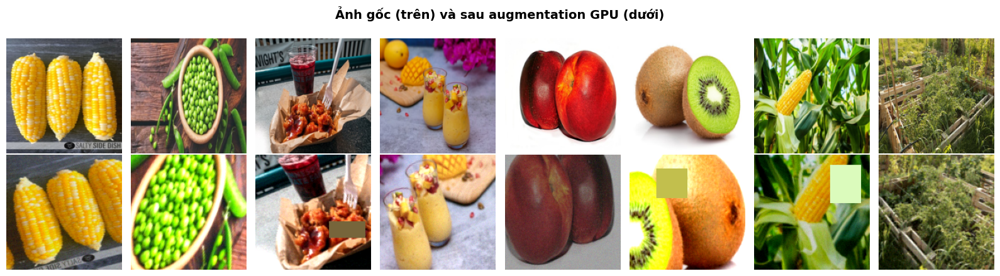

In [17]:
# Minh họa augmentation GPU thật sự được dùng trong lúc train.
_imgs = np.stack([np.asarray(X_train[i], dtype=np.float32) for i in np.random.default_rng(0).choice(len(X_train), 8, replace=False)])
_t = torch.from_numpy(_imgs).permute(0, 3, 1, 2).div(255.0)
_aug = apply_batch_augmentation(_t.to('cuda' if torch.cuda.is_available() else 'cpu')).cpu()
plt.figure(figsize=(16, 4.5))
for i in range(8):
    plt.subplot(2, 8, i + 1); plt.imshow(_t[i].permute(1, 2, 0).numpy()); plt.axis('off')
    plt.subplot(2, 8, i + 9); plt.imshow(_aug[i].permute(1, 2, 0).numpy()); plt.axis('off')
plt.suptitle('Ảnh gốc (trên) và sau augmentation GPU (dưới)', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()


## 7. Thuật toán 2: Fast GPU CNN (PyTorch CUDA)

Cell này train CNN trực tiếp trong notebook bằng GPU.

In [18]:
# Train Fast CNN trực tiếp trong notebook
if RUN_FAST_GPU_TORCH:
    custom_cnn, history_cnn, torch_metadata = train_gpu_model(
        'fast_cnn',
        epochs=TORCH_EPOCHS,
        batch_size=TORCH_BATCH_SIZE,
        pretrained=False,
        freeze_backbone=False,
        workers=TORCH_WORKERS,
    )
    print(f"Fast CNN đã load: {torch_metadata['checkpoint']}", flush=True)
else:
    print('RUN_FAST_GPU_TORCH=False nên bỏ qua Fast CNN GPU.', flush=True)


Fast GPU CNN | full trainable model | GPU: NVIDIA GeForce RTX 4060 Laptop GPU
Images: train=3285 val=821 test=725 | classes=44
Batch size: 128 | epochs: 25 | AMP: True
Epoch 001/25 - training...
Epoch 001/25 - validating...
Epoch 001/25 | train loss 3.6056 acc 0.0883 (27.0s) | val loss 3.7125 acc 0.0426 (3.6s) | best 0.0426
Epoch 002/25 - training...
Epoch 002/25 - validating...
Epoch 002/25 | train loss 3.3867 acc 0.1382 (8.4s) | val loss 3.3439 acc 0.1498 (0.7s) | best 0.1498
Epoch 003/25 - training...
Epoch 003/25 - validating...
Epoch 003/25 | train loss 3.2679 acc 0.1574 (8.2s) | val loss 3.1618 acc 0.1851 (0.4s) | best 0.1851
Epoch 004/25 - training...
Epoch 004/25 - validating...
Epoch 004/25 | train loss 3.1996 acc 0.1619 (8.2s) | val loss 3.1000 acc 0.2034 (0.5s) | best 0.2034
Epoch 005/25 - training...
Epoch 005/25 - validating...
Epoch 005/25 | train loss 3.1446 acc 0.1830 (8.1s) | val loss 3.0788 acc 0.1937 (0.3s) | best 0.2034
Epoch 006/25 - training...
Epoch 006/25 - val

## 8. Thuật toán 3: MobileNetV2 Transfer Learning (PyTorch CUDA)

Cell này train MobileNetV2 trực tiếp trong notebook bằng GPU.

In [19]:
# Train MobileNetV2 trực tiếp trong notebook
if RUN_FAST_GPU_TORCH and RUN_TORCH_TRANSFER_MODELS:
    mobilenet_model, history_2, mobilenet_metadata = train_gpu_model(
        'mobilenetv2',
        epochs=TORCH_TRANSFER_EPOCHS,
        batch_size=TORCH_TRANSFER_BATCH_SIZE,
        pretrained=TORCH_USE_PRETRAINED,
        freeze_backbone=TORCH_FREEZE_BACKBONE,
        learning_rate=2e-4,
        workers=TORCH_WORKERS,
    )
    print(f"MobileNetV2 đã load: {mobilenet_metadata['checkpoint']}", flush=True)
else:
    print('RUN_TORCH_TRANSFER_MODELS=False nên bỏ qua MobileNetV2 GPU.', flush=True)


MobileNetV2 | full trainable model | GPU: NVIDIA GeForce RTX 4060 Laptop GPU
Images: train=3285 val=821 test=725 | classes=44
Batch size: 64 | epochs: 15 | AMP: True
Epoch 001/15 - training...
Epoch 001/15 - validating...
Epoch 001/15 | train loss 3.4197 acc 0.1918 (178.8s) | val loss 2.8962 acc 0.3362 (31.5s) | best 0.3362
Epoch 002/15 - training...
Epoch 002/15 - validating...
Epoch 002/15 | train loss 2.4537 acc 0.4478 (15.9s) | val loss 2.1650 acc 0.5238 (0.5s) | best 0.5238
Epoch 003/15 - training...
Epoch 003/15 - validating...
Epoch 003/15 | train loss 1.8872 acc 0.5756 (15.9s) | val loss 1.7968 acc 0.6127 (0.4s) | best 0.6127
Epoch 004/15 - training...
Epoch 004/15 - validating...
Epoch 004/15 | train loss 1.5589 acc 0.6749 (16.0s) | val loss 1.5948 acc 0.6650 (0.5s) | best 0.6650
Epoch 005/15 - training...
Epoch 005/15 - validating...
Epoch 005/15 | train loss 1.3747 acc 0.7078 (15.9s) | val loss 1.5031 acc 0.6748 (0.5s) | best 0.6748
Epoch 006/15 - training...
Epoch 006/15 -

## 9. Thuật toán 4: EfficientNetB0 Transfer Learning (PyTorch CUDA)

Cell này train EfficientNetB0 trực tiếp trong notebook bằng GPU.

In [20]:
# Train EfficientNetB0 trực tiếp trong notebook
if RUN_FAST_GPU_TORCH and RUN_TORCH_TRANSFER_MODELS:
    efficientnet_model, efficientnet_history_2, efficientnet_metadata = train_gpu_model(
        'efficientnetb0',
        epochs=TORCH_TRANSFER_EPOCHS,
        batch_size=TORCH_TRANSFER_BATCH_SIZE,
        pretrained=TORCH_USE_PRETRAINED,
        freeze_backbone=TORCH_FREEZE_BACKBONE,
        learning_rate=2e-4,
        workers=TORCH_WORKERS,
    )
    print(f"EfficientNetB0 đã load: {efficientnet_metadata['checkpoint']}", flush=True)
else:
    print('RUN_TORCH_TRANSFER_MODELS=False nên bỏ qua EfficientNetB0 GPU.', flush=True)


EfficientNetB0 | full trainable model | GPU: NVIDIA GeForce RTX 4060 Laptop GPU
Images: train=3285 val=821 test=725 | classes=44
Batch size: 64 | epochs: 15 | AMP: True
Epoch 001/15 - training...
Epoch 001/15 - validating...
Epoch 001/15 | train loss 3.3600 acc 0.2414 (203.6s) | val loss 2.6991 acc 0.3983 (25.4s) | best 0.3983
Epoch 002/15 - training...
Epoch 002/15 - validating...
Epoch 002/15 | train loss 2.2811 acc 0.5029 (16.8s) | val loss 1.9928 acc 0.5530 (0.6s) | best 0.5530
Epoch 003/15 - training...
Epoch 003/15 - validating...
Epoch 003/15 | train loss 1.6906 acc 0.6420 (16.8s) | val loss 1.6439 acc 0.6480 (0.5s) | best 0.6480
Epoch 004/15 - training...
Epoch 004/15 - validating...
Epoch 004/15 | train loss 1.4058 acc 0.7087 (16.8s) | val loss 1.5018 acc 0.6797 (0.5s) | best 0.6797
Epoch 005/15 - training...
Epoch 005/15 - validating...
Epoch 005/15 | train loss 1.2184 acc 0.7650 (16.9s) | val loss 1.3712 acc 0.7113 (0.5s) | best 0.7113
Epoch 006/15 - training...
Epoch 006/1

## 10. Thuật toán 5: ResNet50 Transfer Learning (PyTorch CUDA)

Cell này train ResNet50 trực tiếp bằng GPU theo 2 giai đoạn: warm-up custom head rồi fine-tuning các block cuối.


In [21]:
# Train ResNet50 trực tiếp trong notebook bằng PyTorch CUDA
if RUN_FAST_GPU_TORCH and RUN_TORCH_RESNET50:
    resnet_model, resnet_history_2, resnet_metadata = train_resnet50_gpu(
        warmup_epochs=TORCH_RESNET_WARMUP_EPOCHS,
        finetune_epochs=TORCH_RESNET_FINETUNE_EPOCHS,
        batch_size=TORCH_RESNET_BATCH_SIZE,
        pretrained=TORCH_USE_PRETRAINED,
        workers=TORCH_WORKERS,
        train_last_blocks=TORCH_RESNET_FINETUNE_BLOCKS,
        finetune_lr=1e-4,
    )
    print(f"ResNet50 đã load: {resnet_metadata['checkpoint']}", flush=True)
else:
    print('RUN_TORCH_RESNET50=False nên bỏ qua ResNet50 GPU.', flush=True)



ResNet50 | warm-up head + fine-tuning | GPU: NVIDIA GeForce RTX 4060 Laptop GPU
Images: train=3285 val=821 test=725 | classes=44
Batch size: 64 | warm-up: 3 | fine-tune: 15 | AMP: True

[Warm-up Custom Head] lr=0.001 | trainable params=90,156
Epoch 001/18 (Warm-up Custom Head 1/3) - training...
Epoch 001/18 - validating...
Epoch 001/18 | train loss 3.0384 acc 0.3431 (21.4s) | val loss 2.4225 acc 0.5981 (12.2s) | best 0.5981
Epoch 002/18 (Warm-up Custom Head 2/3) - training...
Epoch 002/18 - validating...
Epoch 002/18 | train loss 2.0325 acc 0.6557 (2.4s) | val loss 1.8597 acc 0.7052 (0.7s) | best 0.7052
Epoch 003/18 (Warm-up Custom Head 3/3) - training...
Epoch 003/18 - validating...
Epoch 003/18 | train loss 1.6041 acc 0.7336 (2.4s) | val loss 1.5942 acc 0.7186 (0.7s) | best 0.7186

[Fine-Tuning] lr=0.0001 | trainable params=23,322,668
Epoch 004/18 (Fine-Tuning 1/15) - training...
Epoch 004/18 - validating...
Epoch 004/18 | train loss 1.2530 acc 0.7422 (61.6s) | val loss 1.2120 acc 0

## 9b. Keras/TensorFlow CPU-only đã tắt

Các model TensorFlow/Keras cũ không còn train trong notebook này vì TensorFlow trên Windows native đang CPU-only.

In [22]:
print('Đã tắt các cell Keras/TensorFlow CPU-only. Dùng các cell PyTorch CUDA trực tiếp phía trên để train.')
print(f'PyTorch CUDA={TORCH_CUDA_AVAILABLE} | device={TORCH_DEVICE_NAME}')

Đã tắt các cell Keras/TensorFlow CPU-only. Dùng các cell PyTorch CUDA trực tiếp phía trên để train.
PyTorch CUDA=True | device=NVIDIA GeForce RTX 4060 Laptop GPU


### Lưu model sau khi huấn luyện

Chỉ cần train đầy đủ một lần. Cell này lưu MobileNetV2, EfficientNetB0 và `class_names` ra đĩa để lần sau demo không phải chạy lại toàn bộ notebook.

In [23]:
# Checkpoint được lưu bởi từng cell train GPU.
for metadata_name in ['torch_metadata', 'mobilenet_metadata', 'efficientnet_metadata', 'resnet_metadata']:
    if metadata_name in globals():
        metadata = globals()[metadata_name]
        print(f"{metadata['model_name']}: {metadata['checkpoint']}")

Fast GPU CNN (web): saved_models_torch\fast_cnn_web.pt
MobileNetV2 (web): saved_models_torch\mobilenetv2_web.pt
EfficientNetB0 (web): saved_models_torch\efficientnetb0_web.pt
ResNet50 (web): saved_models_torch\resnet50_web.pt


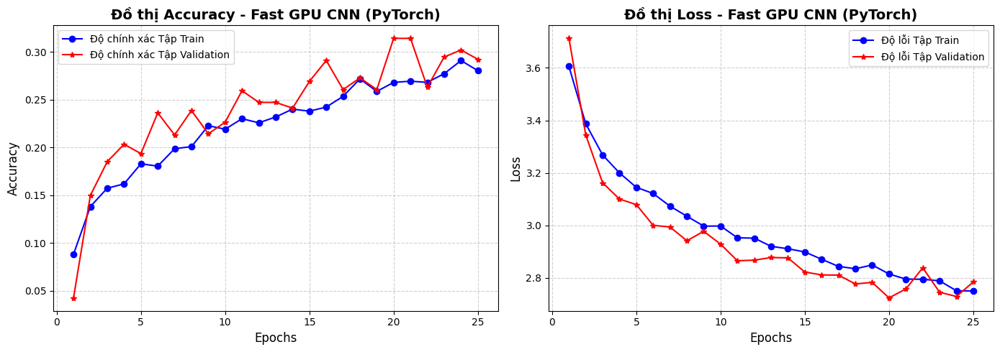

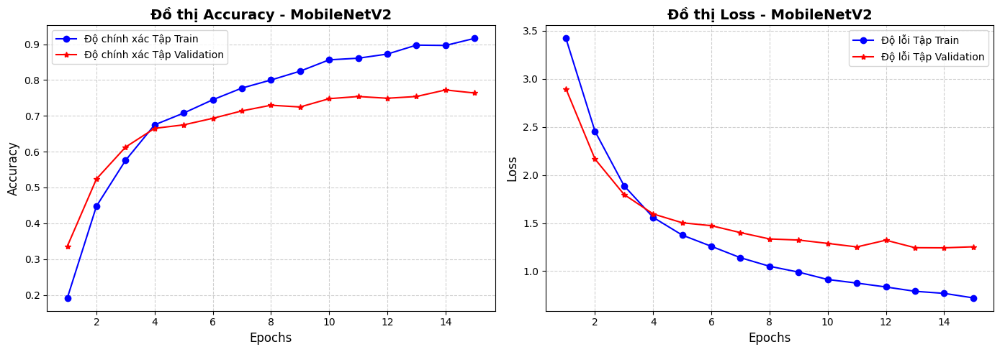

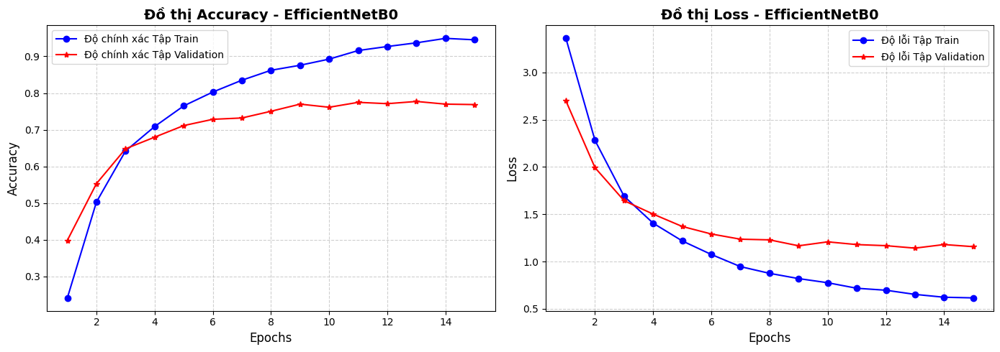

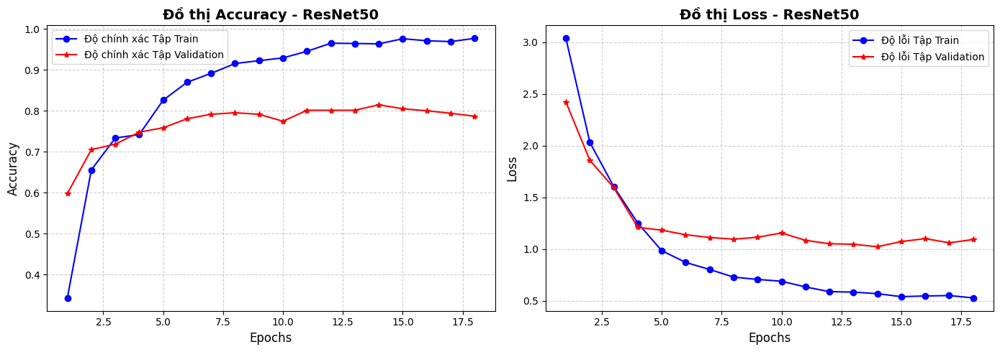

In [24]:
def plot_learning_curves(history, model_name):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs = range(1, len(acc) + 1)

    plt.figure(figsize=(14, 5))
    plt.subplot(1, 2, 1)
    plt.plot(epochs, acc, 'bo-', label='Độ chính xác Tập Train')
    plt.plot(epochs, val_acc, 'r*-', label='Độ chính xác Tập Validation')
    plt.title(f'Đồ thị Accuracy - {model_name}', fontsize=14, fontweight='bold')
    plt.xlabel('Epochs', fontsize=12)
    plt.ylabel('Accuracy', fontsize=12)
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.6)

    plt.subplot(1, 2, 2)
    plt.plot(epochs, loss, 'bo-', label='Độ lỗi Tập Train')
    plt.plot(epochs, val_loss, 'r*-', label='Độ lỗi Tập Validation')
    plt.title(f'Đồ thị Loss - {model_name}', fontsize=14, fontweight='bold')
    plt.xlabel('Epochs', fontsize=12)
    plt.ylabel('Loss', fontsize=12)
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()

history_sources = [
    ('Fast GPU CNN (PyTorch)', 'history_cnn'),
    ('MobileNetV2', 'history_2'),
    ('EfficientNetB0', 'efficientnet_history_2'),
    ('ResNet50', 'resnet_history_2'),
]
for model_name, history_name in history_sources:
    if history_name in globals():
        plot_learning_curves(globals()[history_name], model_name)

## 10. Theo dõi huấn luyện và độ phức tạp mô hình

Ngoài accuracy/loss, số tham số giúp giải thích vì sao transfer learning thường tốt hơn CNN tự xây dựng nhưng vẫn có chi phí tính toán khác nhau.

,model,total_params,trainable_params,non_trainable_params
0,Fast GPU CNN (PyTorch),323532,323532,0
1,MobileNetV2,2280236,2280236,0
2,EfficientNetB0,4063912,4063912,0
3,ResNet50,23598188,23598188,0


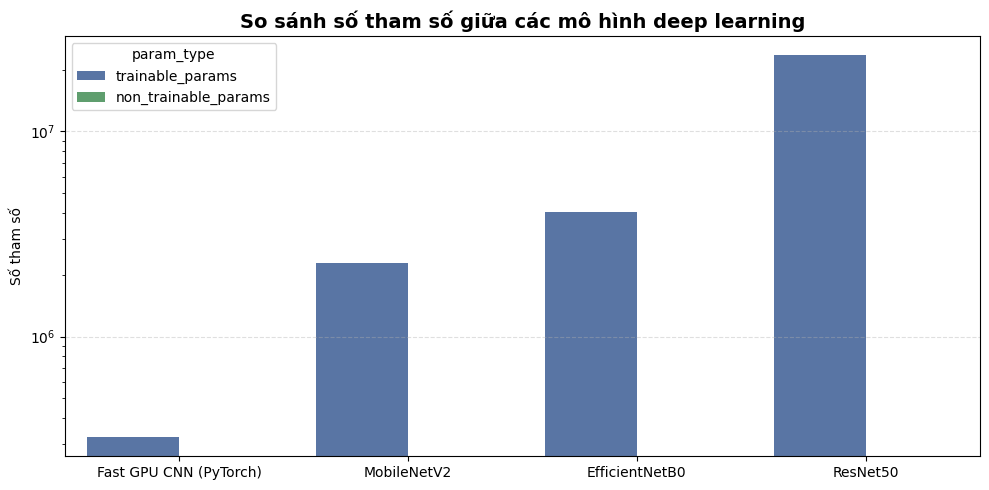

In [25]:
# Bảng độ phức tạp mô hình: tổng tham số và tham số được huấn luyện
model_objects = []
for name, var_name in [
    ('Fast GPU CNN (PyTorch)', 'custom_cnn'),
    ('MobileNetV2', 'mobilenet_model'),
    ('EfficientNetB0', 'efficientnet_model'),
    ('ResNet50', 'resnet_model')
]:
    if var_name in globals():
        model_objects.append((name, globals()[var_name]))

complexity_rows = []
for name, model in model_objects:
    if hasattr(model, 'trainable_weights'):
        trainable_params = int(np.sum([np.prod(v.shape) for v in model.trainable_weights]))
        non_trainable_params = int(np.sum([np.prod(v.shape) for v in getattr(model, 'non_trainable_weights', [])]))
    elif hasattr(model, 'parameters'):
        trainable_params = int(sum(p.numel() for p in model.parameters() if p.requires_grad))
        non_trainable_params = int(sum(p.numel() for p in model.parameters() if not p.requires_grad))
    else:
        trainable_params = 0
        non_trainable_params = 0
    complexity_rows.append({
        'model': name,
        'total_params': trainable_params + non_trainable_params,
        'trainable_params': trainable_params,
        'non_trainable_params': non_trainable_params
    })

complexity_df = pd.DataFrame(complexity_rows)
display(complexity_df)

if not complexity_df.empty:
    plot_df = complexity_df.melt(
        id_vars='model',
        value_vars=['trainable_params', 'non_trainable_params'],
        var_name='param_type',
        value_name='params'
    )
    plt.figure(figsize=(10, 5))
    sns.barplot(data=plot_df, x='model', y='params', hue='param_type', palette=['#4C72B0', '#55A868'])
    plt.title('So sánh số tham số giữa các mô hình deep learning', fontsize=14, fontweight='bold')
    plt.ylabel('Số tham số')
    plt.xlabel('')
    plt.yscale('log')
    plt.grid(axis='y', linestyle='--', alpha=0.4)
    plt.tight_layout()
    plt.show()

## 11. Đánh giá từng mô hình: Classification Report và Confusion Matrix

### SVM + PCA


       BÁO CÁO PHÂN LOẠI (CLASSIFICATION REPORT) - SVM
              precision    recall  f1-score   support

       apple       0.14      0.24      0.18        25
     apricot       0.67      0.15      0.25        13
     avocado       0.00      0.00      0.00        15
      banana       0.13      0.11      0.12        28
        beet       0.20      0.45      0.27        29
    broccoli       0.00      0.00      0.00        13
 cauliflower       0.30      0.32      0.31        19
napa_cabbage       0.00      0.00      0.00         5
     cabbage       0.17      0.14      0.15        14
      carrot       0.26      0.38      0.31        26
        corn       0.18      0.62      0.28        40
    cucumber       0.27      0.17      0.21        18
      daikon       0.00      0.00      0.00         8
      garlic       0.19      0.42      0.26        24
       grape       0.13      0.44      0.20        32
        kiwi       0.17      0.19      0.18        27
       lemon       0.50  

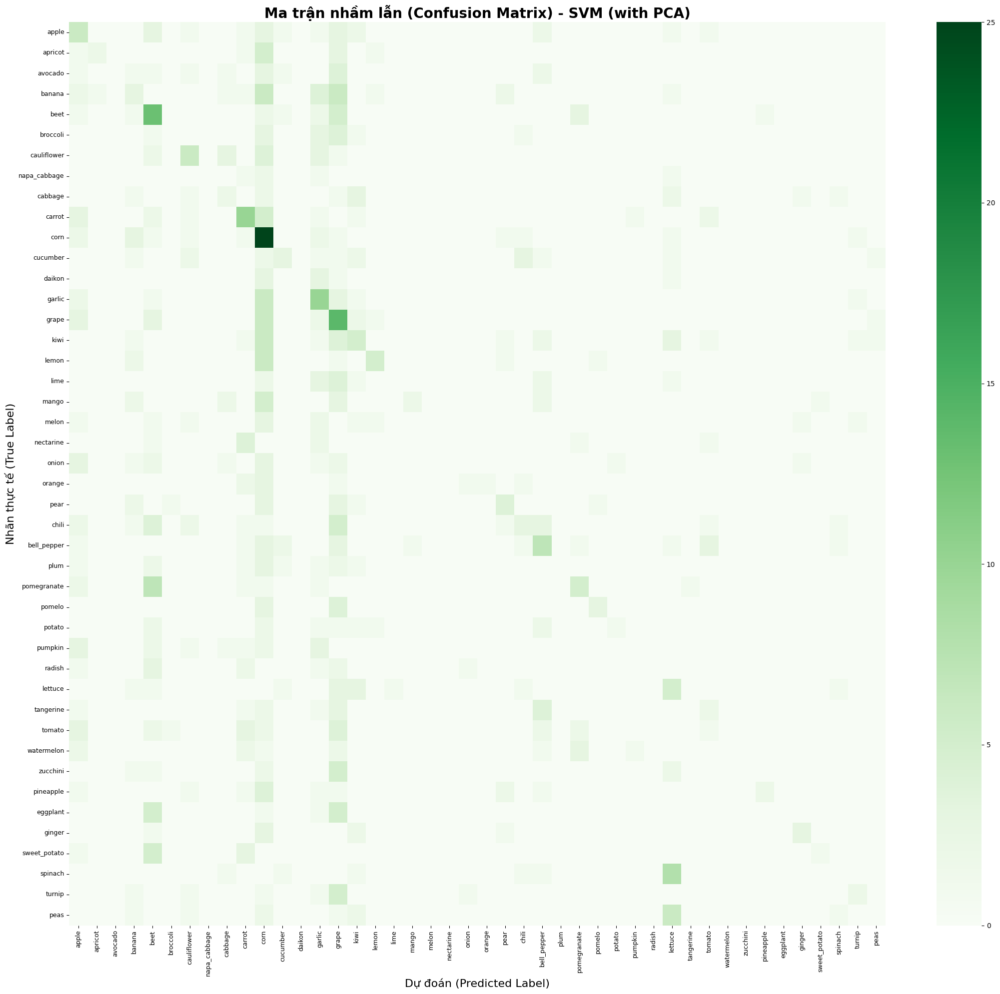

In [26]:

class_names = valid_classes 

# Xử lý nhãn thực tế (y_true_svm) từ tập dữ liệu con y_test_sub
# Kiểm tra nếu y_test_sub đang ở dạng One-hot encoding (mảng 2D) thì chuyển về dạng số nguyên (1D)
if len(y_test_sub.shape) > 1 and y_test_sub.shape[1] > 1:
    y_true_svm = np.argmax(y_test_sub, axis=1)
else:
    y_true_svm = y_test_sub

# Lấy nhãn dự đoán đã có sẵn từ code của bạn
y_pred_classes_svm = y_pred_svm

# In Báo cáo phân loại (Classification Report)
print("\n       BÁO CÁO PHÂN LOẠI (CLASSIFICATION REPORT) - SVM")
print(classification_report(y_true_svm, y_pred_classes_svm, target_names=class_names, zero_division=0))

# Vẽ Ma trận nhầm lẫn (Confusion Matrix)
plt.figure(figsize=(22, 20))
cm_svm = confusion_matrix(y_true_svm, y_pred_classes_svm)

sns.heatmap(cm_svm, annot=False, cmap='Greens', fmt='g', 
            xticklabels=class_names, yticklabels=class_names)

plt.title('Ma trận nhầm lẫn (Confusion Matrix) - SVM (with PCA)', fontsize=20, fontweight='bold')
plt.xlabel('Dự đoán (Predicted Label)', fontsize=16)
plt.ylabel('Nhãn thực tế (True Label)', fontsize=16)
plt.xticks(rotation=90, fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.show()

### Fast GPU CNN (PyTorch CUDA)

       BÁO CÁO PHÂN LOẠI (CLASSIFICATION REPORT) - FAST GPU CNN
              precision    recall  f1-score   support

       apple       0.31      0.16      0.21        25
     apricot       0.00      0.00      0.00        13
     avocado       0.00      0.00      0.00        15
      banana       0.16      0.21      0.18        28
        beet       0.35      0.76      0.48        29
    broccoli       0.10      0.15      0.12        13
 cauliflower       0.24      0.21      0.22        19
napa_cabbage       0.00      0.00      0.00         5
     cabbage       0.21      0.21      0.21        14
      carrot       0.39      0.54      0.45        26
        corn       0.34      0.68      0.45        40
    cucumber       0.38      0.28      0.32        18
      daikon       0.00      0.00      0.00         8
      garlic       0.32      0.50      0.39        24
       grape       0.37      0.59      0.45        32
        kiwi       0.29      0.59      0.39        27
       lemon     

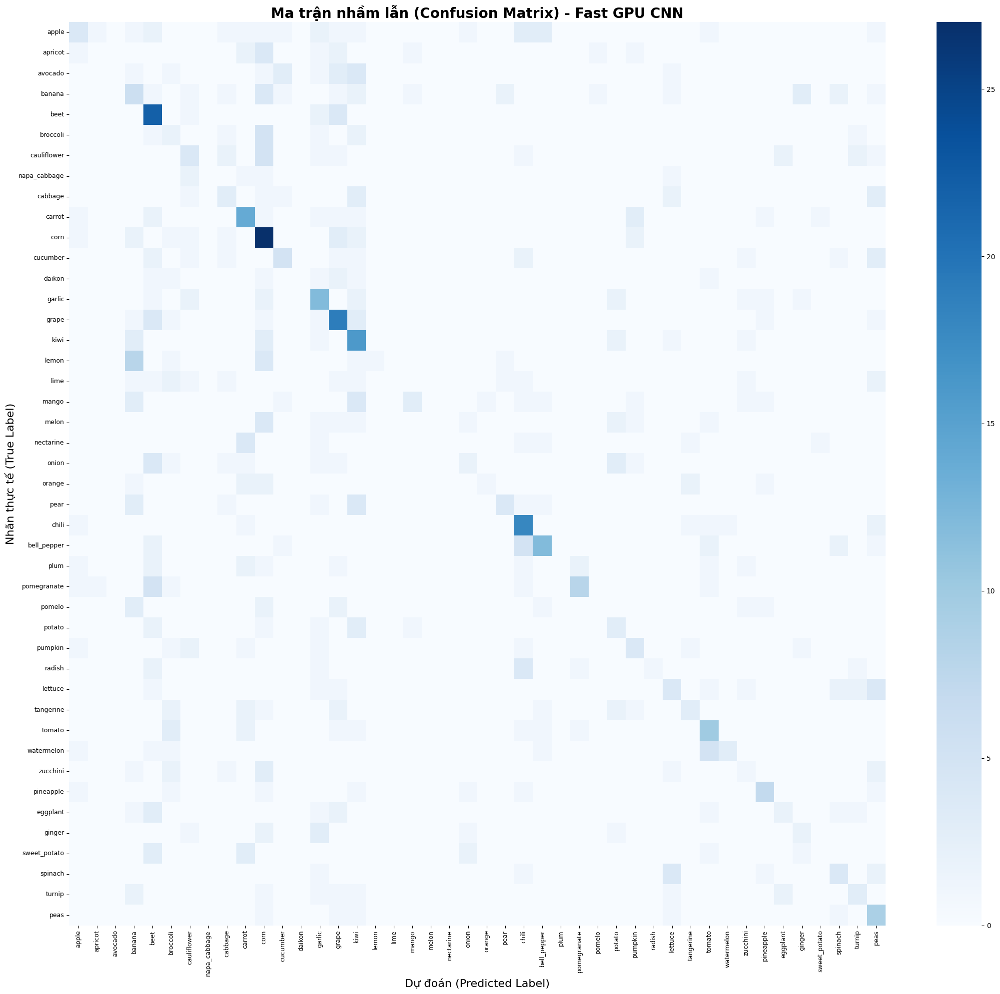

In [27]:
class_names = valid_classes

if 'custom_cnn' not in globals():
    print('Chưa có Fast GPU CNN/Custom CNN, bỏ qua cell này.')
else:
    y_true = []
    y_pred_probs = []

    for images, labels in test_ds:
        preds = custom_cnn.predict(images, verbose=0)
        y_pred_probs.extend(np.argmax(preds, axis=1))
        y_true.extend(np.argmax(labels.numpy(), axis=1))

    y_true = np.array(y_true)
    y_pred_classes = np.array(y_pred_probs)

    print("       BÁO CÁO PHÂN LOẠI (CLASSIFICATION REPORT) - FAST GPU CNN")
    print(classification_report(y_true, y_pred_classes, target_names=class_names, zero_division=0))

    plt.figure(figsize=(22, 20))
    cm = confusion_matrix(y_true, y_pred_classes)
    sns.heatmap(cm, annot=False, cmap='Blues', fmt='g',
                xticklabels=class_names, yticklabels=class_names)
    plt.title('Ma trận nhầm lẫn (Confusion Matrix) - Fast GPU CNN', fontsize=20, fontweight='bold')
    plt.xlabel('Dự đoán (Predicted Label)', fontsize=16)
    plt.ylabel('Nhãn thực tế (True Label)', fontsize=16)
    plt.xticks(rotation=90, fontsize=9)
    plt.yticks(rotation=0, fontsize=9)
    plt.tight_layout()
    plt.show()

### MobileNetV2

       BÁO CÁO PHÂN LOẠI (CLASSIFICATION REPORT) - MOBILENETV2
              precision    recall  f1-score   support

       apple       0.61      0.68      0.64        25
     apricot       0.50      0.54      0.52        13
     avocado       0.70      0.47      0.56        15
      banana       0.73      0.86      0.79        28
        beet       0.85      0.76      0.80        29
    broccoli       0.73      0.85      0.79        13
 cauliflower       0.95      0.95      0.95        19
napa_cabbage       0.00      0.00      0.00         5
     cabbage       0.74      1.00      0.85        14
      carrot       0.85      0.85      0.85        26
        corn       0.92      0.88      0.90        40
    cucumber       0.81      0.72      0.76        18
      daikon       0.50      0.12      0.20         8
      garlic       0.69      0.92      0.79        24
       grape       0.93      0.84      0.89        32
        kiwi       1.00      0.74      0.85        27
       lemon      

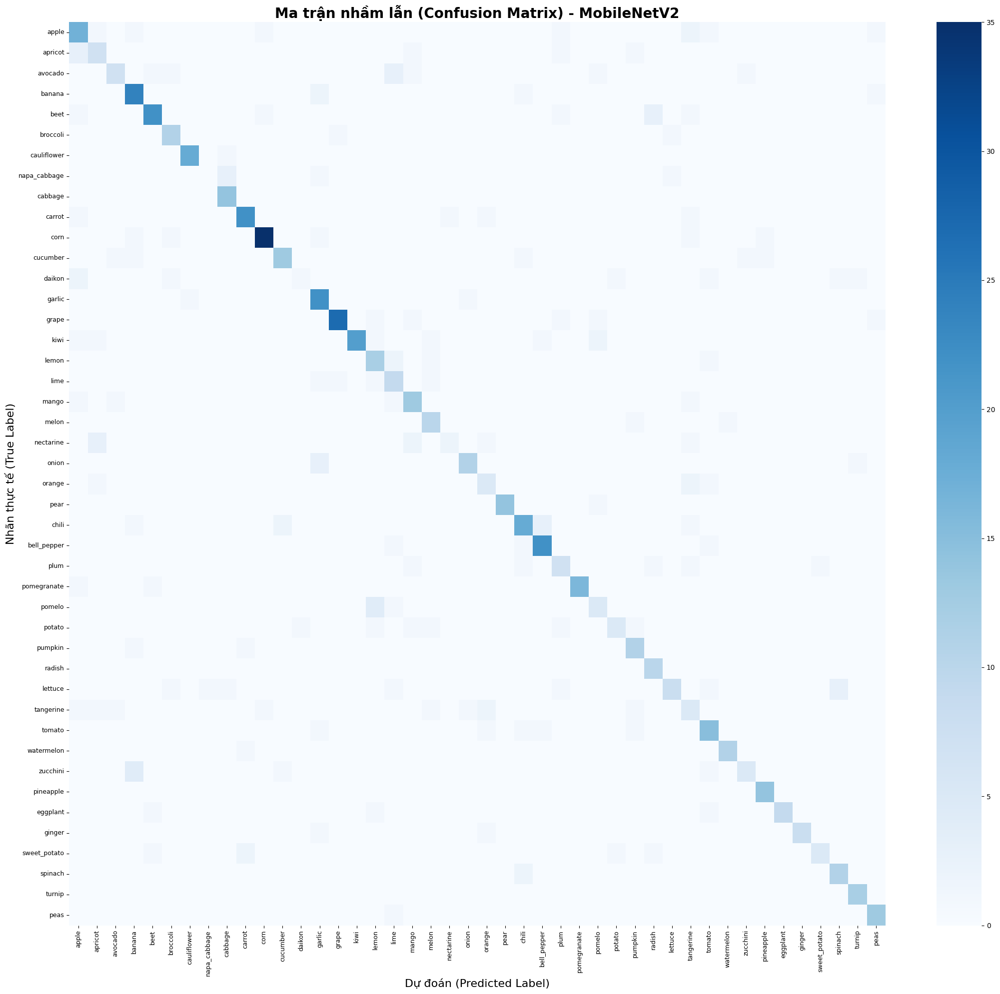

In [28]:
class_names = valid_classes

if 'mobilenet_model' not in globals():
    print('Chưa có MobileNetV2, bỏ qua cell này.')
else:
    y_true_mobilenet = []
    y_pred_classes_mobilenet = []

    for images, labels in test_ds:
        preds = mobilenet_model.predict(images, verbose=0)
        y_pred_classes_mobilenet.extend(np.argmax(preds, axis=1))
        y_true_mobilenet.extend(np.argmax(labels.numpy(), axis=1))

    y_true_mobilenet = np.array(y_true_mobilenet)
    y_pred_classes_mobilenet = np.array(y_pred_classes_mobilenet)

    print("       BÁO CÁO PHÂN LOẠI (CLASSIFICATION REPORT) - MOBILENETV2")
    print(classification_report(y_true_mobilenet, y_pred_classes_mobilenet, target_names=class_names, zero_division=0))

    plt.figure(figsize=(22, 20))
    cm_mobilenet = confusion_matrix(y_true_mobilenet, y_pred_classes_mobilenet)
    sns.heatmap(cm_mobilenet, annot=False, cmap='Blues', fmt='g',
                xticklabels=class_names, yticklabels=class_names)
    plt.title('Ma trận nhầm lẫn (Confusion Matrix) - MobileNetV2', fontsize=20, fontweight='bold')
    plt.xlabel('Dự đoán (Predicted Label)', fontsize=16)
    plt.ylabel('Nhãn thực tế (True Label)', fontsize=16)
    plt.xticks(rotation=90, fontsize=9)
    plt.yticks(rotation=0, fontsize=9)
    plt.tight_layout()
    plt.show()

### EfficientNetB0

       BÁO CÁO PHÂN LOẠI (CLASSIFICATION REPORT) - EFFICIENTNETB0
              precision    recall  f1-score   support

       apple       0.52      0.60      0.56        25
     apricot       0.77      0.77      0.77        13
     avocado       0.88      0.47      0.61        15
      banana       0.71      0.89      0.79        28
        beet       0.68      0.79      0.73        29
    broccoli       0.73      0.85      0.79        13
 cauliflower       0.94      0.89      0.92        19
napa_cabbage       0.50      0.20      0.29         5
     cabbage       0.76      0.93      0.84        14
      carrot       0.88      0.88      0.88        26
        corn       0.90      0.88      0.89        40
    cucumber       0.85      0.61      0.71        18
      daikon       0.50      0.38      0.43         8
      garlic       0.68      0.88      0.76        24
       grape       1.00      0.88      0.93        32
        kiwi       0.81      0.81      0.81        27
       lemon   

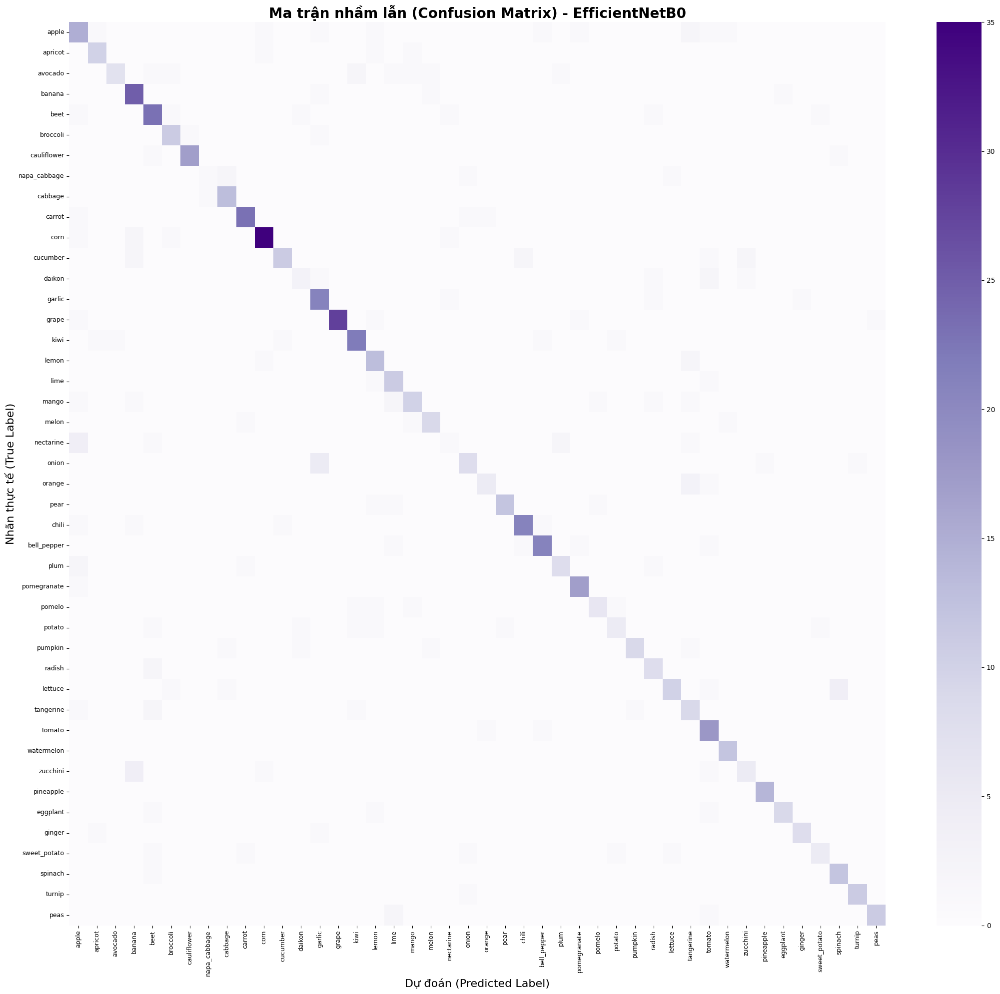

In [29]:
class_names = valid_classes

if 'efficientnet_model' not in globals():
    print('Chưa có EfficientNetB0, bỏ qua cell này.')
else:
    y_true_efficientnet = []
    y_pred_classes_efficientnet = []

    for images, labels in test_ds:
        preds = efficientnet_model.predict(images, verbose=0)
        y_pred_classes_efficientnet.extend(np.argmax(preds, axis=1))
        y_true_efficientnet.extend(np.argmax(labels.numpy(), axis=1))

    y_true_efficientnet = np.array(y_true_efficientnet)
    y_pred_classes_efficientnet = np.array(y_pred_classes_efficientnet)

    print("       BÁO CÁO PHÂN LOẠI (CLASSIFICATION REPORT) - EFFICIENTNETB0")
    print(classification_report(y_true_efficientnet, y_pred_classes_efficientnet, target_names=class_names, zero_division=0))

    plt.figure(figsize=(22, 20))
    cm_efficientnet = confusion_matrix(y_true_efficientnet, y_pred_classes_efficientnet)
    sns.heatmap(cm_efficientnet, annot=False, cmap='Purples', fmt='g',
                xticklabels=class_names, yticklabels=class_names)
    plt.title('Ma trận nhầm lẫn (Confusion Matrix) - EfficientNetB0', fontsize=20, fontweight='bold')
    plt.xlabel('Dự đoán (Predicted Label)', fontsize=16)
    plt.ylabel('Nhãn thực tế (True Label)', fontsize=16)
    plt.xticks(rotation=90, fontsize=9)
    plt.yticks(rotation=0, fontsize=9)
    plt.tight_layout()
    plt.show()

### ResNet50


       BÁO CÁO PHÂN LOẠI (CLASSIFICATION REPORT) - RESNET50
              precision    recall  f1-score   support

       apple       0.74      0.80      0.77        25
     apricot       0.62      0.62      0.62        13
     avocado       0.73      0.73      0.73        15
      banana       0.84      0.96      0.90        28
        beet       0.83      0.83      0.83        29
    broccoli       0.77      0.77      0.77        13
 cauliflower       0.76      1.00      0.86        19
napa_cabbage       0.25      0.20      0.22         5
     cabbage       0.73      0.79      0.76        14
      carrot       0.85      0.85      0.85        26
        corn       0.93      0.97      0.95        40
    cucumber       0.94      0.89      0.91        18
      daikon       0.50      0.12      0.20         8
      garlic       0.71      0.83      0.77        24
       grape       0.91      0.91      0.91        32
        kiwi       1.00      0.89      0.94        27
       lemon       0.

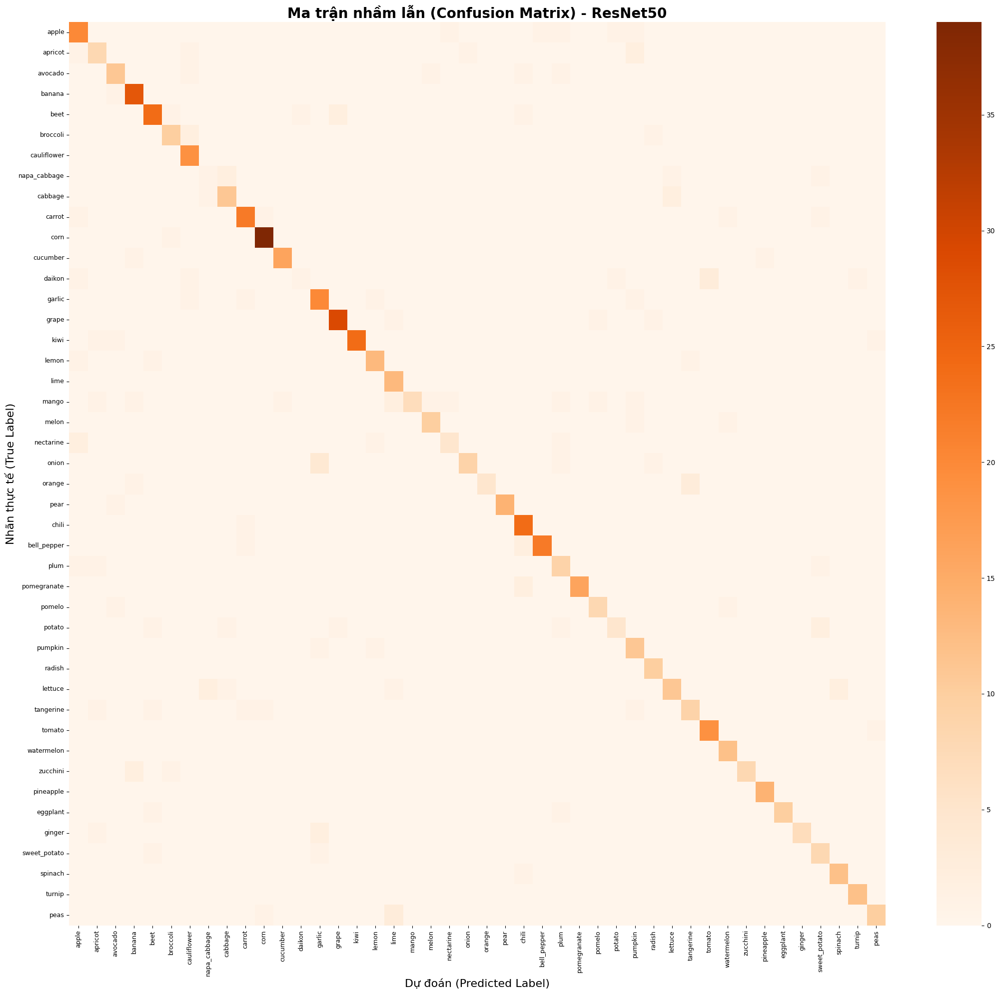

In [30]:
class_names = valid_classes

if 'resnet_model' not in globals():
    print('Chưa có ResNet50, bỏ qua cell này.')
else:
    y_true_resnet = []
    y_pred_classes_resnet = []

    for images, labels in test_ds:
        preds = resnet_model.predict(images, verbose=0)
        y_pred_classes_resnet.extend(np.argmax(preds, axis=1))
        y_true_resnet.extend(np.argmax(labels.numpy(), axis=1))

    y_true_resnet = np.array(y_true_resnet)
    y_pred_classes_resnet = np.array(y_pred_classes_resnet)

    print('       BÁO CÁO PHÂN LOẠI (CLASSIFICATION REPORT) - RESNET50')
    print(classification_report(y_true_resnet, y_pred_classes_resnet, target_names=class_names, zero_division=0))

    plt.figure(figsize=(22, 20))
    cm_resnet = confusion_matrix(y_true_resnet, y_pred_classes_resnet)
    sns.heatmap(cm_resnet, annot=False, cmap='Oranges', fmt='g',
                xticklabels=class_names, yticklabels=class_names)
    plt.title('Ma trận nhầm lẫn (Confusion Matrix) - ResNet50', fontsize=20, fontweight='bold')
    plt.xlabel('Dự đoán (Predicted Label)', fontsize=16)
    plt.ylabel('Nhãn thực tế (True Label)', fontsize=16)
    plt.xticks(rotation=90, fontsize=9)
    plt.yticks(rotation=0, fontsize=9)
    plt.tight_layout()
    plt.show()


In [31]:
from IPython.display import display

# Hàm đếm số lượng nhãn từ tf.data.Dataset 
def count_labels_from_dataset(dataset, num_classes):
    counts = np.zeros(num_classes, dtype=int)
    # Duyệt qua từng batch trong dataset
    for images, labels in dataset:
        counts += np.sum(labels.numpy(), axis=0).astype(int)
    return counts

# Tiến hành đếm
train_counts = count_labels_from_dataset(train_ds, NUM_CLASSES)
val_counts = count_labels_from_dataset(val_ds, NUM_CLASSES)
test_counts = count_labels_from_dataset(test_ds, NUM_CLASSES)

total_counts = train_counts + val_counts + test_counts

# Tạo bảng dữ liệu Pandas
df_stats = pd.DataFrame({
    'STT': np.arange(1, NUM_CLASSES + 1),
    'Tên lớp trái cây': valid_classes,
    'Số ảnh Train': train_counts,
    'Số ảnh Val (từ Train)': val_counts,
    'Số ảnh Test': test_counts,
    'Tổng số ảnh': total_counts
})

cols_to_format = ['Số ảnh Train', 'Số ảnh Val (từ Train)', 'Số ảnh Test', 'Tổng số ảnh']
for col in cols_to_format:
    df_stats[col] = df_stats[col].apply(lambda x: f"{x:,}")

pd.set_option('display.max_rows', None) 
# -----------------------------------------------------

# In ra màn hình Notebook
print(f"\n Bảng thống kê chi tiết {NUM_CLASSES} lớp trái cây:")
display(df_stats)


 Bảng thống kê chi tiết 44 lớp trái cây:


,STT,Tên lớp trái cây,Số ảnh Train,Số ảnh Val (từ Train),Số ảnh Test,Tổng số ảnh
0,1,apple,114,28,25,167
1,2,apricot,60,15,13,88
2,3,avocado,66,17,15,98
3,4,banana,126,31,28,185
4,5,beet,132,33,29,194
5,6,broccoli,59,15,13,87
6,7,cauliflower,87,22,19,128
7,8,napa_cabbage,19,5,5,29
8,9,cabbage,65,16,14,95
9,10,carrot,118,30,26,174


,model,accuracy,f1_macro
0,SVM (PCA),0.198621,0.143043
1,Fast GPU CNN (PyTorch),0.329655,0.240273
2,MobileNetV2,0.753103,0.704889
3,EfficientNetB0,0.762759,0.724955
4,ResNet50,0.820690,0.780592


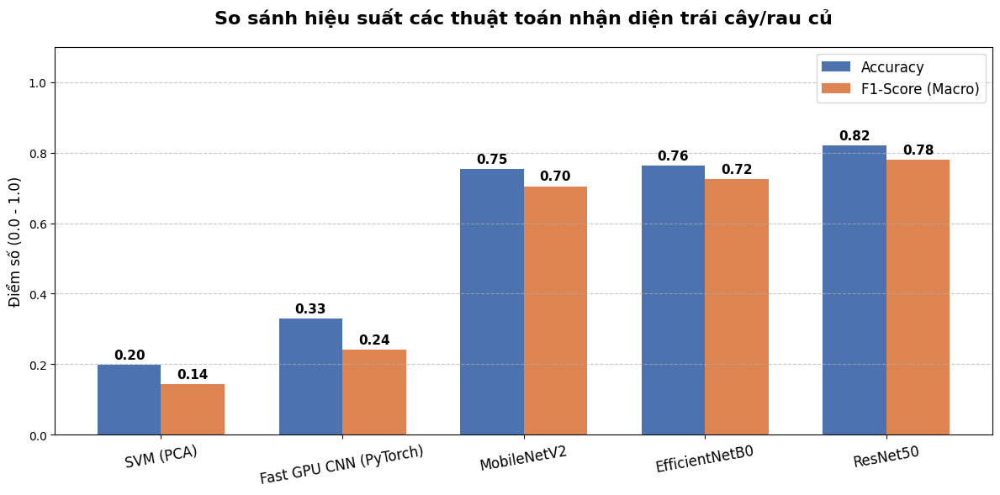

In [32]:
from sklearn.metrics import f1_score

comparison_rows = []

if 'y_true_svm' in globals() and 'y_pred_classes_svm' in globals():
    comparison_rows.append({
        'model': 'SVM (PCA)',
        'accuracy': accuracy_score(y_true_svm, y_pred_classes_svm),
        'f1_macro': f1_score(y_true_svm, y_pred_classes_svm, average='macro', zero_division=0)
    })

if 'y_true' in globals() and 'y_pred_classes' in globals():
    comparison_rows.append({
        'model': 'Fast GPU CNN (PyTorch)',
        'accuracy': accuracy_score(y_true, y_pred_classes),
        'f1_macro': f1_score(y_true, y_pred_classes, average='macro', zero_division=0)
    })

if 'y_true_mobilenet' in globals() and 'y_pred_classes_mobilenet' in globals():
    comparison_rows.append({
        'model': 'MobileNetV2',
        'accuracy': accuracy_score(y_true_mobilenet, y_pred_classes_mobilenet),
        'f1_macro': f1_score(y_true_mobilenet, y_pred_classes_mobilenet, average='macro', zero_division=0)
    })

if 'y_true_efficientnet' in globals() and 'y_pred_classes_efficientnet' in globals():
    comparison_rows.append({
        'model': 'EfficientNetB0',
        'accuracy': accuracy_score(y_true_efficientnet, y_pred_classes_efficientnet),
        'f1_macro': f1_score(y_true_efficientnet, y_pred_classes_efficientnet, average='macro', zero_division=0)
    })

if 'y_true_resnet' in globals() and 'y_pred_classes_resnet' in globals():
    comparison_rows.append({
        'model': 'ResNet50',
        'accuracy': accuracy_score(y_true_resnet, y_pred_classes_resnet),
        'f1_macro': f1_score(y_true_resnet, y_pred_classes_resnet, average='macro', zero_division=0)
    })

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)

if not comparison_df.empty:
    x = np.arange(len(comparison_df))
    width = 0.35
    fig, ax = plt.subplots(figsize=(12, 6))
    rects1 = ax.bar(x - width/2, comparison_df['accuracy'], width, label='Accuracy', color='#4C72B0')
    rects2 = ax.bar(x + width/2, comparison_df['f1_macro'], width, label='F1-Score (Macro)', color='#DD8452')
    ax.set_ylabel('Điểm số (0.0 - 1.0)', fontsize=12)
    ax.set_title('So sánh hiệu suất các thuật toán nhận diện trái cây/rau củ', fontsize=16, fontweight='bold', pad=20)
    ax.set_xticks(x)
    ax.set_xticklabels(comparison_df['model'], fontsize=12, rotation=10)
    ax.legend(fontsize=12)
    ax.set_ylim(0, 1.1)

    for rects in [rects1, rects2]:
        for rect in rects:
            height = rect.get_height()
            ax.annotate(f'{height:.2f}', xy=(rect.get_x() + rect.get_width() / 2, height),
                        xytext=(0, 3), textcoords='offset points', ha='center', va='bottom',
                        fontsize=11, fontweight='bold')

    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

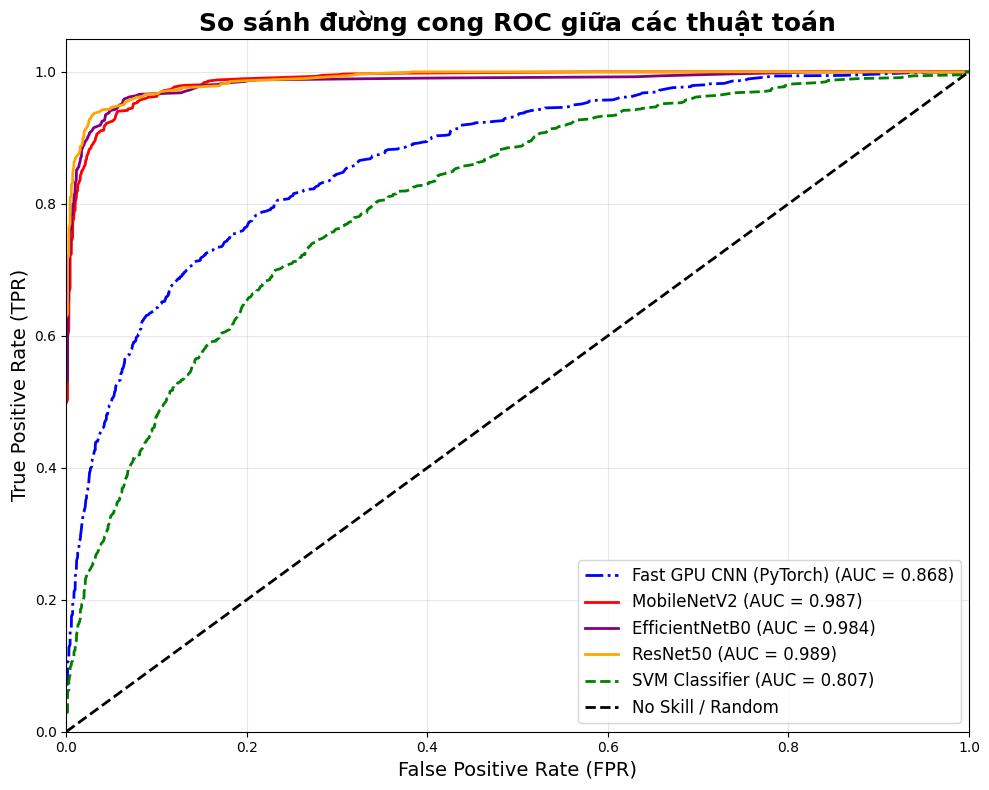

In [33]:
from sklearn.metrics import roc_curve, auc

y_true_onehot = []
for images, labels in test_ds:
    y_true_onehot.extend(labels.numpy())
y_true_onehot = np.array(y_true_onehot)
n_classes = len(class_names)

def compute_macro_roc(y_true, y_pred, n_classes):
    fpr_dict = {}
    tpr_dict = {}
    for i in range(n_classes):
        fpr_dict[i], tpr_dict[i], _ = roc_curve(y_true[:, i], y_pred[:, i])
    all_fpr = np.unique(np.concatenate([fpr_dict[i] for i in range(n_classes)]))
    mean_tpr = np.zeros_like(all_fpr)
    for i in range(n_classes):
        mean_tpr += np.interp(all_fpr, fpr_dict[i], tpr_dict[i])
    mean_tpr /= n_classes
    return all_fpr, mean_tpr, auc(all_fpr, mean_tpr)

roc_sources = []
if 'custom_cnn' in globals():
    roc_sources.append(('Fast GPU CNN (PyTorch)', custom_cnn.predict(test_ds, verbose=0), 'blue', '-.'))
if 'mobilenet_model' in globals():
    roc_sources.append(('MobileNetV2', mobilenet_model.predict(test_ds, verbose=0), 'red', '-'))
if 'efficientnet_model' in globals():
    roc_sources.append(('EfficientNetB0', efficientnet_model.predict(test_ds, verbose=0), 'purple', '-'))
if 'resnet_model' in globals():
    roc_sources.append(('ResNet50', resnet_model.predict(test_ds, verbose=0), 'orange', '-'))
if 'svm_model' in globals() and 'X_test_pca' in globals():
    y_test_sub_onehot = to_categorical(y_test_sub, num_classes=n_classes)
    roc_sources.append(('SVM Classifier', svm_model.predict_proba(X_test_pca), 'green', '--'))

if roc_sources:
    plt.figure(figsize=(10, 8))
    for model_name, y_pred, color, linestyle in roc_sources:
        y_true_for_model = y_test_sub_onehot if model_name == 'SVM Classifier' else y_true_onehot
        fpr, tpr, roc_auc = compute_macro_roc(y_true_for_model, y_pred, n_classes)
        plt.plot(fpr, tpr, color=color, linewidth=2, linestyle=linestyle, label=f'{model_name} (AUC = {roc_auc:.3f})')

    plt.plot([0, 1], [0, 1], 'k--', lw=2, label='No Skill / Random')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate (FPR)', fontsize=14)
    plt.ylabel('True Positive Rate (TPR)', fontsize=14)
    plt.title('So sánh đường cong ROC giữa các thuật toán', fontsize=18, fontweight='bold')
    plt.legend(loc='lower right', fontsize=12)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    print('Chưa có mô hình nào để vẽ ROC.')

### Dự đoán mẫu giữa các mô hình transfer learning

Grid này rất hữu ích khi bảo vệ vì thể hiện mô hình hoạt động trên ảnh cụ thể, không chỉ trên con số tổng hợp.

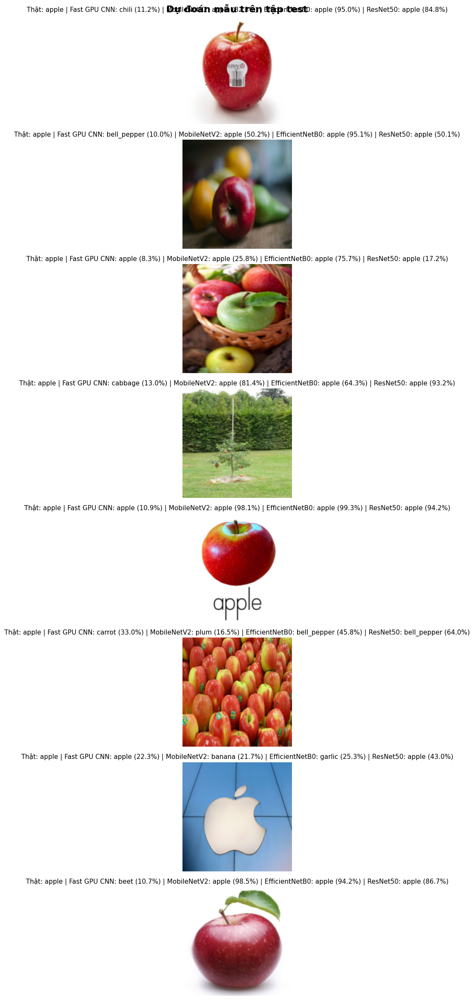

In [34]:
# So sánh dự đoán mẫu giữa các mô hình đã huấn luyện
def show_model_prediction_grid(models, dataset, class_names, n=8):
    images, labels = next(iter(dataset))
    n = min(n, images.shape[0])
    plt.figure(figsize=(18, 3 * n))
    for i in range(n):
        true_idx = int(np.argmax(labels[i].numpy()))
        img = images[i:i+1]
        plt.subplot(n, 1, i + 1)
        plt.imshow(images[i].numpy().astype('uint8'))
        plt.axis('off')
        pred_texts = [f'Thật: {class_names[true_idx]}']
        for model_name, model in models:
            probs = model.predict(img, verbose=0)[0]
            pred_idx = int(np.argmax(probs))
            pred_texts.append(f'{model_name}: {class_names[pred_idx]} ({probs[pred_idx]:.1%})')
        plt.title(' | '.join(pred_texts), fontsize=11)
    plt.suptitle('Dự đoán mẫu trên tập test', fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.show()

prediction_models = []
if 'custom_cnn' in globals():
    prediction_models.append(('Fast GPU CNN', custom_cnn))
if 'mobilenet_model' in globals():
    prediction_models.append(('MobileNetV2', mobilenet_model))
if 'efficientnet_model' in globals():
    prediction_models.append(('EfficientNetB0', efficientnet_model))
if 'resnet_model' in globals():
    prediction_models.append(('ResNet50', resnet_model))

if prediction_models:
    show_model_prediction_grid(prediction_models, test_ds, class_names, n=8)
else:
    print('Hãy huấn luyện ít nhất một mô hình trước khi chạy cell này.')

## 12. Phân tích lỗi nâng cao và Grad-CAM

Phần mở rộng này so sánh sâu hơn các mô hình, chỉ ra lớp nào còn dễ nhầm, và trực quan hóa vùng ảnh mà MobileNetV2/EfficientNetB0 dùng để đưa ra dự đoán.

===== Fast GPU CNN (PyTorch) =====
Accuracy: 0.3297
Balanced accuracy: 0.2573
Top-5 accuracy: 0.6441

10 lớp khó nhất theo F1-score:


,class_name,precision,recall,f1_score,support
1,apricot,0.0,0.0,0.0,13
2,avocado,0.0,0.0,0.0,15
7,napa_cabbage,0.0,0.0,0.0,5
12,daikon,0.0,0.0,0.0,8
26,plum,0.0,0.0,0.0,12
20,nectarine,0.0,0.0,0.0,9
19,melon,0.0,0.0,0.0,12
17,lime,0.0,0.0,0.0,13
28,pomelo,0.0,0.0,0.0,10
40,sweet_potato,0.0,0.0,0.0,10


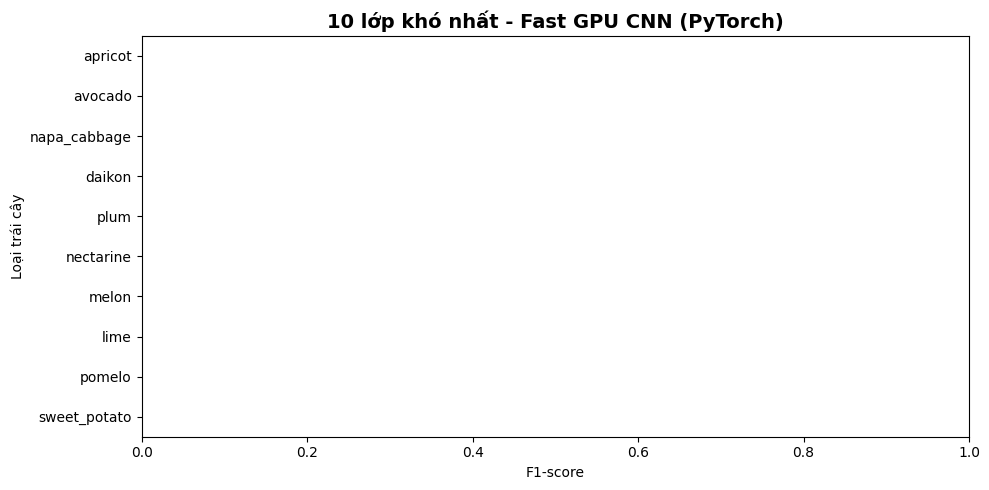

===== MobileNetV2 =====
Accuracy: 0.7531
Balanced accuracy: 0.7113
Top-5 accuracy: 0.9324

10 lớp khó nhất theo F1-score:


,class_name,precision,recall,f1_score,support
7,napa_cabbage,0.000000,0.000000,0.000000,5
12,daikon,0.500000,0.125000,0.200000,8
20,nectarine,0.666667,0.222222,0.333333,9
33,tangerine,0.312500,0.357143,0.333333,14
28,pomelo,0.500000,0.500000,0.500000,10
22,orange,0.454545,0.555556,0.500000,9
1,apricot,0.500000,0.538462,0.518519,13
29,potato,0.714286,0.454545,0.555556,11
36,zucchini,0.714286,0.454545,0.555556,11
2,avocado,0.700000,0.466667,0.560000,15


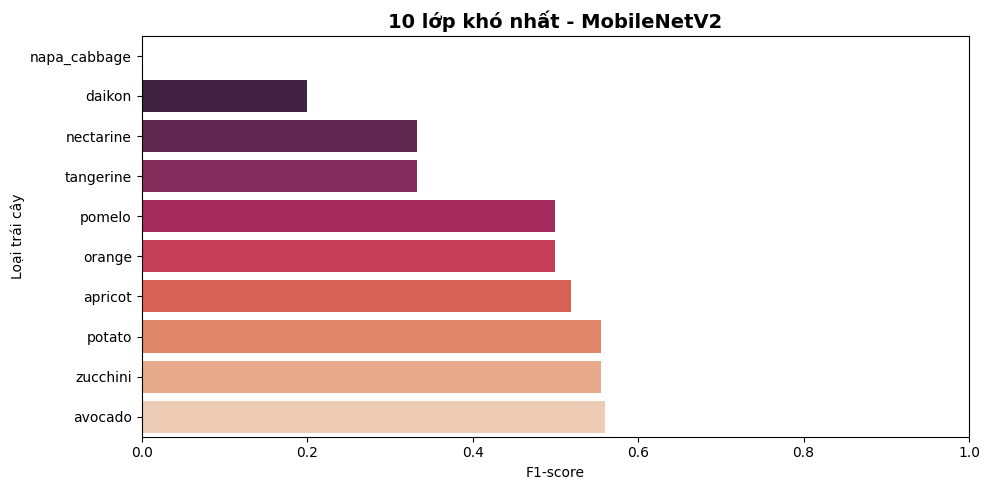

===== EfficientNetB0 =====
Accuracy: 0.7628
Balanced accuracy: 0.7227
Top-5 accuracy: 0.9531

10 lớp khó nhất theo F1-score:


,class_name,precision,recall,f1_score,support
20,nectarine,0.250000,0.111111,0.153846,9
7,napa_cabbage,0.500000,0.200000,0.285714,5
12,daikon,0.500000,0.375000,0.428571,8
29,potato,0.625000,0.454545,0.526316,11
36,zucchini,0.625000,0.454545,0.526316,11
33,tangerine,0.473684,0.642857,0.545455,14
0,apple,0.517241,0.600000,0.555556,25
40,sweet_potato,0.714286,0.500000,0.588235,10
21,onion,0.666667,0.533333,0.592593,15
2,avocado,0.875000,0.466667,0.608696,15


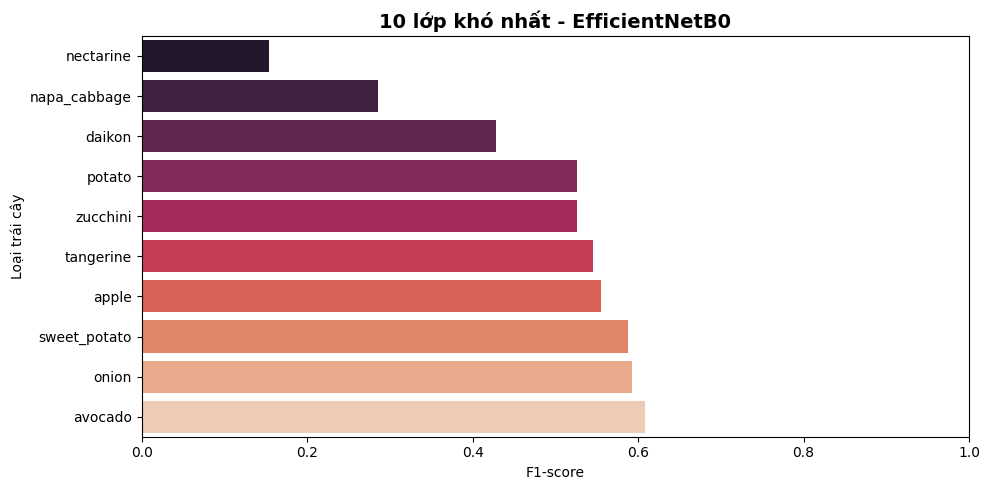

===== ResNet50 =====
Accuracy: 0.8207
Balanced accuracy: 0.7813
Top-5 accuracy: 0.9448

10 lớp khó nhất theo F1-score:


,class_name,precision,recall,f1_score,support
12,daikon,0.500000,0.125000,0.200000,8
7,napa_cabbage,0.250000,0.200000,0.222222,5
29,potato,0.714286,0.454545,0.555556,11
18,mango,1.000000,0.411765,0.583333,17
1,apricot,0.615385,0.615385,0.615385,13
20,nectarine,0.714286,0.555556,0.625000,9
26,plum,0.562500,0.750000,0.642857,12
33,tangerine,0.692308,0.642857,0.666667,14
40,sweet_potato,0.615385,0.800000,0.695652,10
32,lettuce,0.785714,0.647059,0.709677,17


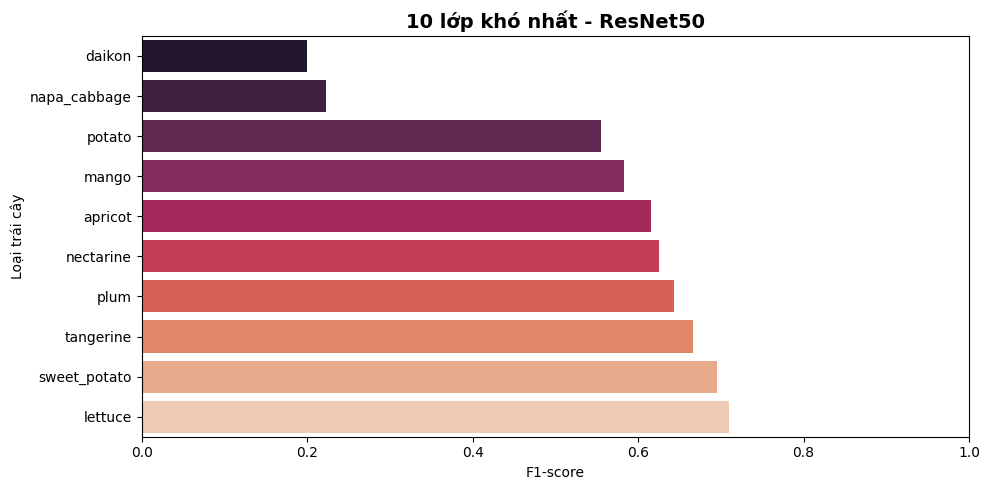

In [35]:
# Đánh giá nâng cao: Top-k accuracy, balanced accuracy và các lớp khó nhất
from sklearn.metrics import precision_recall_fscore_support, balanced_accuracy_score, top_k_accuracy_score

def collect_predictions(model, dataset):
    y_true, y_prob = [], []
    for images, labels in dataset:
        probs = model.predict(images, verbose=0)
        y_prob.append(probs)
        y_true.append(np.argmax(labels.numpy(), axis=1))
    return np.concatenate(y_true), np.concatenate(y_prob)

def advanced_error_analysis(model, dataset, class_names, model_name='Model', top_n=10):
    y_true, y_prob = collect_predictions(model, dataset)
    y_pred = np.argmax(y_prob, axis=1)
    precision, recall, f1, support = precision_recall_fscore_support(
        y_true, y_pred, labels=np.arange(len(class_names)), zero_division=0
    )
    result_df = pd.DataFrame({
        'class_name': class_names,
        'precision': precision,
        'recall': recall,
        'f1_score': f1,
        'support': support
    }).sort_values('f1_score', ascending=True)

    print(f'===== {model_name} =====')
    print(f'Accuracy: {(y_true == y_pred).mean():.4f}')
    print(f'Balanced accuracy: {balanced_accuracy_score(y_true, y_pred):.4f}')
    print(f'Top-5 accuracy: {top_k_accuracy_score(y_true, y_prob, labels=np.arange(len(class_names)), k=5):.4f}')
    print(f'\n{top_n} lớp khó nhất theo F1-score:')
    display(result_df.head(top_n))

    plt.figure(figsize=(10, 5))
    sns.barplot(data=result_df.head(top_n), x='f1_score', y='class_name', palette='rocket', hue='class_name', legend=False)
    plt.title(f'{top_n} lớp khó nhất - {model_name}', fontsize=14, fontweight='bold')
    plt.xlabel('F1-score')
    plt.ylabel('Loại trái cây')
    plt.xlim(0, 1)
    plt.tight_layout()
    plt.show()
    return result_df, y_true, y_prob

if 'custom_cnn' in globals():
    cnn_error_df, cnn_y_true, cnn_y_prob = advanced_error_analysis(custom_cnn, test_ds, class_names, 'Fast GPU CNN (PyTorch)')
if 'mobilenet_model' in globals():
    mobilenet_error_df, mobilenet_y_true, mobilenet_y_prob = advanced_error_analysis(mobilenet_model, test_ds, class_names, 'MobileNetV2')
if 'efficientnet_model' in globals():
    efficientnet_error_df, efficientnet_y_true, efficientnet_y_prob = advanced_error_analysis(efficientnet_model, test_ds, class_names, 'EfficientNetB0')
if 'resnet_model' in globals():
    resnet_error_df, resnet_y_true, resnet_y_prob = advanced_error_analysis(resnet_model, test_ds, class_names, 'ResNet50')


### Trực quan hóa lớp khó và lỗi sai

Hai biểu đồ dưới đây giúp trả lời câu hỏi thường gặp khi bảo vệ: mô hình sai ở lớp nào, và ảnh sai trông như thế nào.

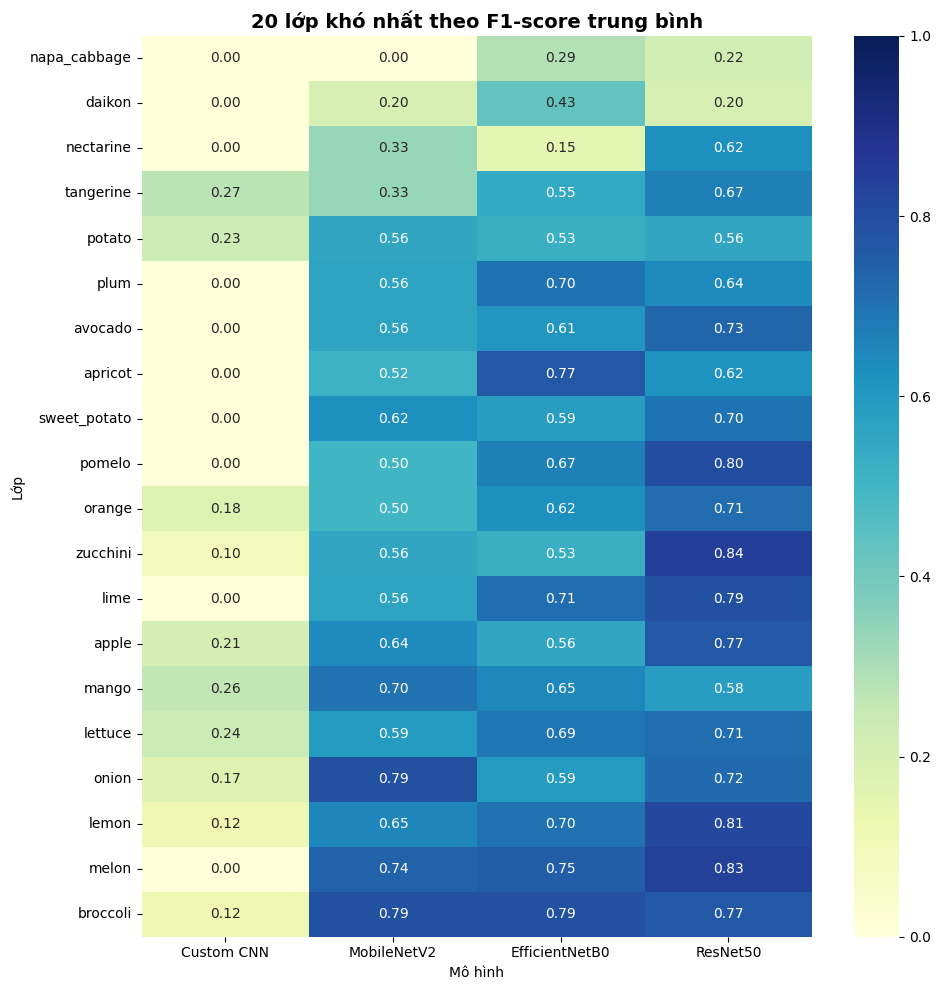

In [36]:
# Heatmap F1-score theo lớp cho các mô hình deep learning
f1_sources = []
if 'cnn_error_df' in globals():
    f1_sources.append(('Custom CNN', cnn_error_df))
if 'mobilenet_error_df' in globals():
    f1_sources.append(('MobileNetV2', mobilenet_error_df))
if 'efficientnet_error_df' in globals():
    f1_sources.append(('EfficientNetB0', efficientnet_error_df))
if 'resnet_error_df' in globals():
    f1_sources.append(('ResNet50', resnet_error_df))

if f1_sources:
    f1_matrix = pd.DataFrame({'class_name': class_names})
    for model_name, df in f1_sources:
        f1_matrix = f1_matrix.merge(
            df[['class_name', 'f1_score']].rename(columns={'f1_score': model_name}),
            on='class_name',
            how='left'
        )

    f1_matrix = f1_matrix.set_index('class_name')
    hardest_classes = f1_matrix.mean(axis=1).sort_values().head(20).index

    plt.figure(figsize=(10, 10))
    sns.heatmap(f1_matrix.loc[hardest_classes], annot=True, fmt='.2f', cmap='YlGnBu', vmin=0, vmax=1)
    plt.title('20 lớp khó nhất theo F1-score trung bình', fontsize=14, fontweight='bold')
    plt.xlabel('Mô hình')
    plt.ylabel('Lớp')
    plt.tight_layout()
    plt.show()
else:
    print('Hãy chạy cell phân tích lỗi nâng cao trước khi vẽ heatmap F1 theo lớp.')


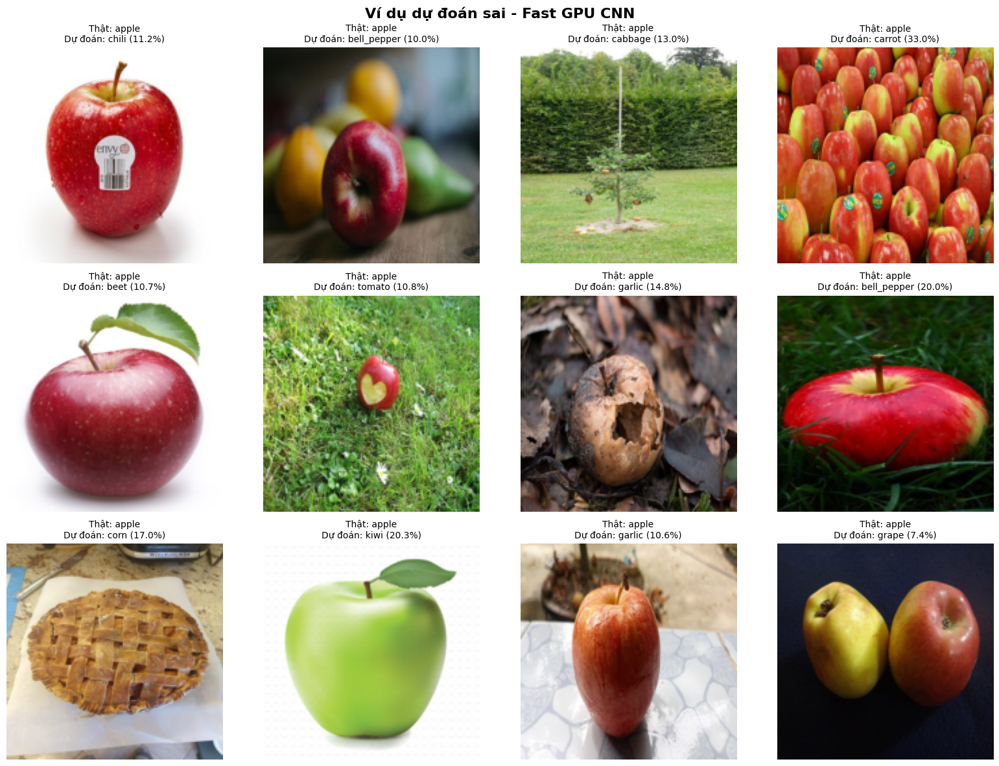

In [37]:
# Hiển thị các ảnh dự đoán sai để phân tích nguyên nhân
def show_misclassified_examples(model, dataset, class_names, model_name='Model', max_examples=12):
    wrong_examples = []
    for images, labels in dataset:
        probs = model.predict(images, verbose=0)
        preds = np.argmax(probs, axis=1)
        true = np.argmax(labels.numpy(), axis=1)
        for i in range(images.shape[0]):
            if preds[i] != true[i]:
                wrong_examples.append((images[i].numpy().astype('uint8'), true[i], preds[i], probs[i][preds[i]]))
                if len(wrong_examples) >= max_examples:
                    break
        if len(wrong_examples) >= max_examples:
            break

    if not wrong_examples:
        print(f'{model_name}: chưa tìm thấy ảnh dự đoán sai trong các batch đã duyệt.')
        return

    cols = 4
    rows = int(np.ceil(len(wrong_examples) / cols))
    plt.figure(figsize=(16, 4 * rows))
    for idx, (img, true_idx, pred_idx, conf) in enumerate(wrong_examples):
        plt.subplot(rows, cols, idx + 1)
        plt.imshow(img)
        plt.axis('off')
        plt.title(f'Thật: {class_names[true_idx]}\nDự đoán: {class_names[pred_idx]} ({conf:.1%})', fontsize=10)
    plt.suptitle(f'Ví dụ dự đoán sai - {model_name}', fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.show()

if 'custom_cnn' in globals():
    show_misclassified_examples(custom_cnn, test_ds, class_names, model_name='Fast GPU CNN', max_examples=12)
elif 'efficientnet_model' in globals():
    show_misclassified_examples(efficientnet_model, test_ds, class_names, model_name='EfficientNetB0', max_examples=12)
else:
    print('Hãy huấn luyện một mô hình trước khi chạy cell này.')

In [38]:
# Grad-CAM cho các mô hình Keras nếu đã bật RUN_SLOW_KERAS_MODELS=True.
KERAS_GRADCAM_MODELS = []
if 'mobilenet_model' in globals() and hasattr(mobilenet_model, 'layers'):
    KERAS_GRADCAM_MODELS.append(('MobileNetV2', mobilenet_model))
if 'efficientnet_model' in globals() and hasattr(efficientnet_model, 'layers'):
    KERAS_GRADCAM_MODELS.append(('EfficientNetB0', efficientnet_model))

if not KERAS_GRADCAM_MODELS:
    print('Bỏ qua Grad-CAM vì các model hiện tại đang là PyTorch CUDA wrapper. Bật cell Keras nếu cần Grad-CAM Keras.')
else:
    def find_last_conv_layer(model):
        for layer in reversed(model.layers):
            if isinstance(layer, Conv2D):
                return layer.name
        raise ValueError('Không tìm thấy lớp Conv2D trong mô hình.')

    def make_gradcam_heatmap(img_array, model, last_conv_layer_name=None, pred_index=None):
        if last_conv_layer_name is None:
            last_conv_layer_name = find_last_conv_layer(model)
        grad_model = Model(model.inputs, [model.get_layer(last_conv_layer_name).output, model.output])
        with tf.GradientTape() as tape:
            conv_outputs, predictions = grad_model(img_array)
            if pred_index is None:
                pred_index = tf.argmax(predictions[0])
            class_channel = predictions[:, pred_index]
        grads = tape.gradient(class_channel, conv_outputs)
        pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
        conv_outputs = conv_outputs[0]
        heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
        heatmap = tf.squeeze(heatmap)
        heatmap = tf.maximum(heatmap, 0) / (tf.reduce_max(heatmap) + 1e-8)
        return heatmap.numpy(), int(pred_index), predictions.numpy()[0]

    def show_gradcam_examples(model, dataset, class_names, model_name='Model', n=6):
        images, labels = next(iter(dataset))
        n = min(n, images.shape[0])
        last_conv_layer_name = find_last_conv_layer(model)
        plt.figure(figsize=(14, 3 * n))
        for i in range(n):
            img = images[i:i+1]
            true_idx = int(np.argmax(labels[i].numpy()))
            heatmap, pred_idx, probs = make_gradcam_heatmap(img, model, last_conv_layer_name)
            original = images[i].numpy().astype('uint8')
            heatmap_resized = cv2.resize(heatmap, (original.shape[1], original.shape[0]))
            heatmap_color = np.uint8(255 * heatmap_resized)
            heatmap_color = cv2.applyColorMap(heatmap_color, cv2.COLORMAP_JET)
            heatmap_color = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB)
            overlay = np.uint8(0.6 * original + 0.4 * heatmap_color)
            plt.subplot(n, 2, 2 * i + 1)
            plt.imshow(original)
            plt.axis('off')
            plt.title(f'Thật: {class_names[true_idx]}')
            plt.subplot(n, 2, 2 * i + 2)
            plt.imshow(overlay)
            plt.axis('off')
            plt.title(f'Dự đoán: {class_names[pred_idx]} ({probs[pred_idx]:.2%})')
        plt.suptitle(f'Grad-CAM - Vùng ảnh {model_name} tập trung khi phân loại', fontsize=16, fontweight='bold')
        plt.tight_layout()
        plt.show()

    if 'mobilenet_model' in globals():
        show_gradcam_examples(mobilenet_model, test_ds, class_names, model_name='MobileNetV2', n=6)
    if 'efficientnet_model' in globals():
        show_gradcam_examples(efficientnet_model, test_ds, class_names, model_name='EfficientNetB0', n=6)

Bỏ qua Grad-CAM vì các model hiện tại đang là PyTorch CUDA wrapper. Bật cell Keras nếu cần Grad-CAM Keras.


## Lưu Model



In [39]:
# Chọn model demo tốt nhất từ các checkpoint PyTorch đã lưu
from pathlib import Path
import importlib
import pandas as pd

import app as fruit_demo_app
fruit_demo_app = importlib.reload(fruit_demo_app)

DEMO_MODEL_DIR = Path(PROJECT_ROOT) / 'saved_models_torch'
demo_candidates = fruit_demo_app.collect_model_candidates(DEMO_MODEL_DIR)

if not demo_candidates:
    raise FileNotFoundError(
        f'Chưa tìm thấy checkpoint PyTorch hợp lệ trong {DEMO_MODEL_DIR}. '
        'Hãy chạy phần train GPU trước hoặc kiểm tra thư mục saved_models_torch.'
    )

demo_ranking = (
    pd.DataFrame([
        {
            'model': item['model_name'],
            'test_accuracy': item['test_accuracy'],
            'best_val_accuracy': item['best_val_accuracy'],
            'image_size': item['image_size'],
            'checkpoint': item['checkpoint_path'].name,
        }
        for item in demo_candidates
    ])
    .sort_values('test_accuracy', ascending=False)
    .reset_index(drop=True)
)
display(demo_ranking.style.format({
    'test_accuracy': '{:.2%}',
    'best_val_accuracy': lambda value: 'N/A' if pd.isna(value) else f'{value:.2%}',
}))

demo_bundle = fruit_demo_app.load_best_model(DEMO_MODEL_DIR)
demo_model = demo_bundle
demo_torch_model = demo_bundle.model
demo_model_name = demo_bundle.model_name
class_names = demo_bundle.class_names
demo_model_test_accuracy = demo_bundle.test_accuracy

print(
    f'Demo tự động chọn: {demo_model_name} | '
    f'test accuracy: {demo_model_test_accuracy:.2%} | '
    f'thiết bị: {demo_bundle.device}'
)


,model,test_accuracy,best_val_accuracy,image_size,checkpoint
0,ResNet50,89.29%,91.59%,64,resnet50_64.pt
1,ResNet50 (web),82.07%,81.49%,160,resnet50_web.pt
2,Fast GPU CNN,81.66%,83.76%,64,fast_fruit_cnn_64.pt
3,EfficientNetB0 (web),76.00%,77.71%,160,efficientnetb0_web.pt
4,MobileNetV2 (web),75.31%,77.22%,160,mobilenetv2_web.pt
5,MobileNetV2,57.83%,60.08%,64,mobilenetv2_64.pt
6,EfficientNetB0,47.48%,49.01%,64,efficientnetb0_64.pt
7,Fast GPU CNN (web),32.83%,31.43%,160,fast_cnn_web.pt


Demo tự động chọn: ResNet50 (web) | test accuracy: 82.07% | thiết bị: cuda


In [40]:
# Dự đoán một ảnh thật bên ngoài tập test để dùng khi demo/thuyết trình
from PIL import Image

REAL_IMAGE_PATH = 'demo_apple_google.jpg'


def predict_single_image(image_path, bundle=None, top_k=5):
    if bundle is None:
        if 'demo_bundle' not in globals():
            raise RuntimeError('Chưa có demo_bundle. Hãy chạy cell chọn model demo trước.')
        bundle = demo_bundle

    image_path = Path(image_path)
    if not image_path.exists():
        raise FileNotFoundError(f'Không đọc được ảnh: {image_path}')

    image = Image.open(image_path).convert('RGB')
    _, _, rows = fruit_demo_app.format_prediction_outputs(image, bundle, top_k=top_k)

    plt.figure(figsize=(5, 5))
    plt.imshow(image)
    plt.axis('off')
    plt.title(f'Dự đoán: {rows[0][1]} ({rows[0][2]})')
    plt.show()

    return pd.DataFrame(rows, columns=['rank', 'class_name', 'probability'])


if 'demo_bundle' not in globals():
    print('Chưa có demo_bundle được chọn theo test accuracy.')
elif Path(REAL_IMAGE_PATH).exists():
    print(f'Demo bằng model: {demo_model_name}')
    display(predict_single_image(REAL_IMAGE_PATH, demo_bundle))
else:
    print(f'Hãy tải một ảnh thật từ Google, lưu thành {REAL_IMAGE_PATH}, rồi chạy lại cell này.')


Hãy tải một ảnh thật từ Google, lưu thành demo_apple_google.jpg, rồi chạy lại cell này.


In [41]:
# Bảng xếp hạng mô hình sau khi đã chạy các cell đánh giá
if 'comparison_df' in globals() and not comparison_df.empty:
    ranking_df = comparison_df.sort_values(['f1_macro', 'accuracy'], ascending=False).reset_index(drop=True)
    ranking_df.index = ranking_df.index + 1
    display(ranking_df)

    best_model = ranking_df.iloc[0]
    print(
        f"Mô hình tốt nhất theo macro F1 hiện tại là {best_model['model']} "
        f"với F1={best_model['f1_macro']:.4f}, Accuracy={best_model['accuracy']:.4f}."
    )
else:
    print('Hãy chạy các cell classification report và biểu đồ so sánh trước để tạo comparison_df.')


,model,accuracy,f1_macro
1,ResNet50,0.820690,0.780592
2,EfficientNetB0,0.762759,0.724955
3,MobileNetV2,0.753103,0.704889
4,Fast GPU CNN (PyTorch),0.329655,0.240273
5,SVM (PCA),0.198621,0.143043


Mô hình tốt nhất theo macro F1 hiện tại là ResNet50 với F1=0.7806, Accuracy=0.8207.


## 13. Demo Web UI bằng Gradio

Giao diện tự động dùng checkpoint PyTorch có `test_accuracy` cao nhất, hiển thị top-5 dự đoán và một số ảnh mẫu từ tập test.


In [42]:
# Demo Web UI Gradio nâng cấp
import importlib
from pathlib import Path

try:
    gr = importlib.import_module('gradio')
except ModuleNotFoundError as exc:
    raise ModuleNotFoundError('Chưa cài Gradio. Hãy chạy: %pip install gradio') from exc

# Luôn nạp lại app.py để nhận thay đổi mới (ví dụ đổi tên web).
import app as fruit_demo_app
fruit_demo_app = importlib.reload(fruit_demo_app)

if 'demo_bundle' not in globals():
    demo_model_dir = Path(globals().get('PROJECT_ROOT', '.')) / 'saved_models_torch'
    demo_bundle = fruit_demo_app.load_best_model(demo_model_dir)
    demo_model = demo_bundle
    demo_torch_model = demo_bundle.model
    demo_model_name = demo_bundle.model_name
    class_names = demo_bundle.class_names
    demo_model_test_accuracy = demo_bundle.test_accuracy

demo = fruit_demo_app.build_demo(demo_bundle, top_k=5)

# Đặt share=True nếu cần tạo link public qua Internet.
fruit_demo_app.launch_demo(demo, share=False)


* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.
